In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

import numpy as np


import pandas as pd
from matplotlib import pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

**LOAD DATASET**

In [ ]:
DATA_PATH = "Tree_Sterility_Dataset.csv"

df = pd.read_csv(DATA_PATH, na_values=["", " ", "NA", "NaN"])

print("Shape:", df.shape)
df.head()


Shape: (2783, 24)


,No,Plot,Subplot,Species,Light_ISF,Light_Cat,Core,Soil,Adult,Sterile,...,AMF,EMF,Phenolics,Lignin,NSC,Census,Time,Event,Harvest,Alive
0,126,1,C,Acer saccharum,0.106,Med,2017,Prunus serotina,I,Non-Sterile,...,22.00,NaN,-0.56,13.86,12.15,4,14.0,1.0,NaN,NaN
1,11,1,C,Quercus alba,0.106,Med,2017,Quercus rubra,970,Non-Sterile,...,15.82,31.07,5.19,20.52,19.29,33,115.5,0.0,NaN,X
2,12,1,C,Quercus rubra,0.106,Med,2017,Prunus serotina,J,Non-Sterile,...,24.45,28.19,3.36,24.74,15.01,18,63.0,1.0,NaN,NaN
3,2823,7,D,Acer saccharum,0.080,Med,2016,Prunus serotina,J,Non-Sterile,...,22.23,NaN,-0.71,14.29,12.36,4,14.0,1.0,NaN,NaN
4,5679,14,A,Acer saccharum,0.060,Low,2017,Prunus serotina,689,Non-Sterile,...,21.15,NaN,-0.58,10.85,11.20,4,14.0,1.0,NaN,NaN


**EDA ANALYSIS**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2783 entries, 0 to 2782
Data columns (total 24 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   No           2783 non-null   int64  
 1   Plot         2783 non-null   int64  
 2   Subplot      2783 non-null   object 
 3   Species      2783 non-null   object 
 4   Light_ISF    2783 non-null   float64
 5   Light_Cat    2783 non-null   object 
 6   Core         2783 non-null   int64  
 7   Soil         2783 non-null   object 
 8   Adult        2783 non-null   object 
 9   Sterile      2783 non-null   object 
 10  Conspecific  2783 non-null   object 
 11  Myco         2783 non-null   object 
 12  SoilMyco     2783 non-null   object 
 13  PlantDate    2783 non-null   object 
 14  AMF          2783 non-null   float64
 15  EMF          1283 non-null   float64
 16  Phenolics    2783 non-null   float64
 17  Lignin       2783 non-null   float64
 18  NSC          2783 non-null   float64
 19  Census

HOW MANY FEATURES?

In [ ]:
print(f"features (excluding the target-Sterile): {df.shape[1]-1}")

features (excluding the target-Sterile): 23


HOW MANY DATA POINTS?

In [ ]:
print(f"data points: {df.shape[0]}")

data points: 2783


In [ ]:
import pandas as pd

# Load dataset
df = pd.read_csv("Tree_Sterility_Dataset.csv")

# Show first few rows (optional)
print(df.head())

# Total number of datapoints (rows) and features (columns)
print("Total datapoints (rows):", df.shape[0])
print("Total features (columns):", df.shape[1])


     No  Plot Subplot         Species  Light_ISF Light_Cat  Core  \
0   126     1       C  Acer saccharum      0.106       Med  2017   
1    11     1       C    Quercus alba      0.106       Med  2017   
2    12     1       C   Quercus rubra      0.106       Med  2017   
3  2823     7       D  Acer saccharum      0.080       Med  2016   
4  5679    14       A  Acer saccharum      0.060       Low  2017   

              Soil Adult      Sterile  ...    AMF    EMF Phenolics Lignin  \
0  Prunus serotina     I  Non-Sterile  ...  22.00    NaN     -0.56  13.86   
1    Quercus rubra   970  Non-Sterile  ...  15.82  31.07      5.19  20.52   
2  Prunus serotina     J  Non-Sterile  ...  24.45  28.19      3.36  24.74   
3  Prunus serotina     J  Non-Sterile  ...  22.23    NaN     -0.71  14.29   
4  Prunus serotina   689  Non-Sterile  ...  21.15    NaN     -0.58  10.85   

     NSC  Census   Time  Event  Harvest  Alive  
0  12.15       4   14.0    1.0      NaN    NaN  
1  19.29      33  115.5    0.0

What kind of features are in your dataset? (Quantitative / Categorical)

In [ ]:
# numerical features
numerical_data = df.select_dtypes(include=['int64', 'float64'])
numerical_features = numerical_data.columns.tolist()

# categorical features
categorical_data = df.select_dtypes(include='object')
categorical_features = categorical_data.columns.tolist()

quantitative_features = numerical_features.copy()

# Print results
print(f"Feature types:\n")
print(f'There are {len(categorical_features)} categorical features:\n{categorical_features}\n')
print(f'There are {len(quantitative_features)} quantitative features:\n{quantitative_features}')

Feature types:

There are 12 categorical features:
['Subplot', 'Species', 'Light_Cat', 'Soil', 'Adult', 'Sterile', 'Conspecific', 'Myco', 'SoilMyco', 'PlantDate', 'Harvest', 'Alive']

There are 12 quantitative features:
['No', 'Plot', 'Light_ISF', 'Core', 'AMF', 'EMF', 'Phenolics', 'Lignin', 'NSC', 'Census', 'Time', 'Event']


In [ ]:
numerical_data.describe().T

,count,mean,std,min,25%,50%,75%,max
No,2783.0,3914.513834,2253.515063,3.000,1971.000,3932.000,5879.000,7772.000
Plot,2783.0,9.561624,5.203659,1.000,5.000,10.000,14.000,18.000
Light_ISF,2783.0,0.085707,0.025638,0.032,0.066,0.082,0.100,0.161
Core,2783.0,2016.648940,0.477387,2016.000,2016.000,2017.000,2017.000,2017.000
AMF,2783.0,20.553069,12.309587,0.000,13.400,18.000,24.445,100.000
EMF,1283.0,26.476750,16.636890,0.000,13.780,27.720,35.710,87.500
Phenolics,2783.0,1.933105,1.969842,-1.350,0.170,0.750,3.780,6.100
Lignin,2783.0,15.759792,6.779607,2.230,10.355,14.040,21.115,32.770
NSC,2783.0,14.219641,4.298271,4.300,11.605,12.660,17.275,29.450
Census,2783.0,15.282070,9.166555,4.000,7.000,13.000,18.000,33.000


In [ ]:
#checking variance
numerical_data.var()

,0
No,5.078330e+06
Plot,2.707807e+01
Light_ISF,6.572914e-04
Core,2.278988e-01
AMF,1.515259e+02
EMF,2.767861e+02
Phenolics,3.880277e+00
Lignin,4.596307e+01
NSC,1.847513e+01
Census,8.402573e+01


In [ ]:
numerical_data.skew()

,0
No,-0.013436
Plot,-0.012063
Light_ISF,0.658495
Core,-0.624428
AMF,1.530073
EMF,0.504768
Phenolics,0.325592
Lignin,0.141701
NSC,0.569887
Census,1.033268


In [ ]:
categorical_data.describe().T

,count,unique,top,freq
Subplot,2783,5,A,701
Species,2783,4,Acer saccharum,751
Light_Cat,2783,3,Med,1474
Soil,2783,7,Sterile,423
Adult,2783,36,I,90
Sterile,2783,2,Non-Sterile,2360
Conspecific,2783,3,Heterospecific,1974
Myco,2783,2,AMF,1500
SoilMyco,2783,3,AMF,1186
PlantDate,2783,19,6/7/18,340


HISTOGRAM AND BOX PLOT

array([[<Axes: title={'center': 'No'}>, <Axes: title={'center': 'Plot'}>,
        <Axes: title={'center': 'Light_ISF'}>],
       [<Axes: title={'center': 'Core'}>,
        <Axes: title={'center': 'AMF'}>, <Axes: title={'center': 'EMF'}>],
       [<Axes: title={'center': 'Phenolics'}>,
        <Axes: title={'center': 'Lignin'}>,
        <Axes: title={'center': 'NSC'}>],
       [<Axes: title={'center': 'Census'}>,
        <Axes: title={'center': 'Time'}>,
        <Axes: title={'center': 'Event'}>]], dtype=object)

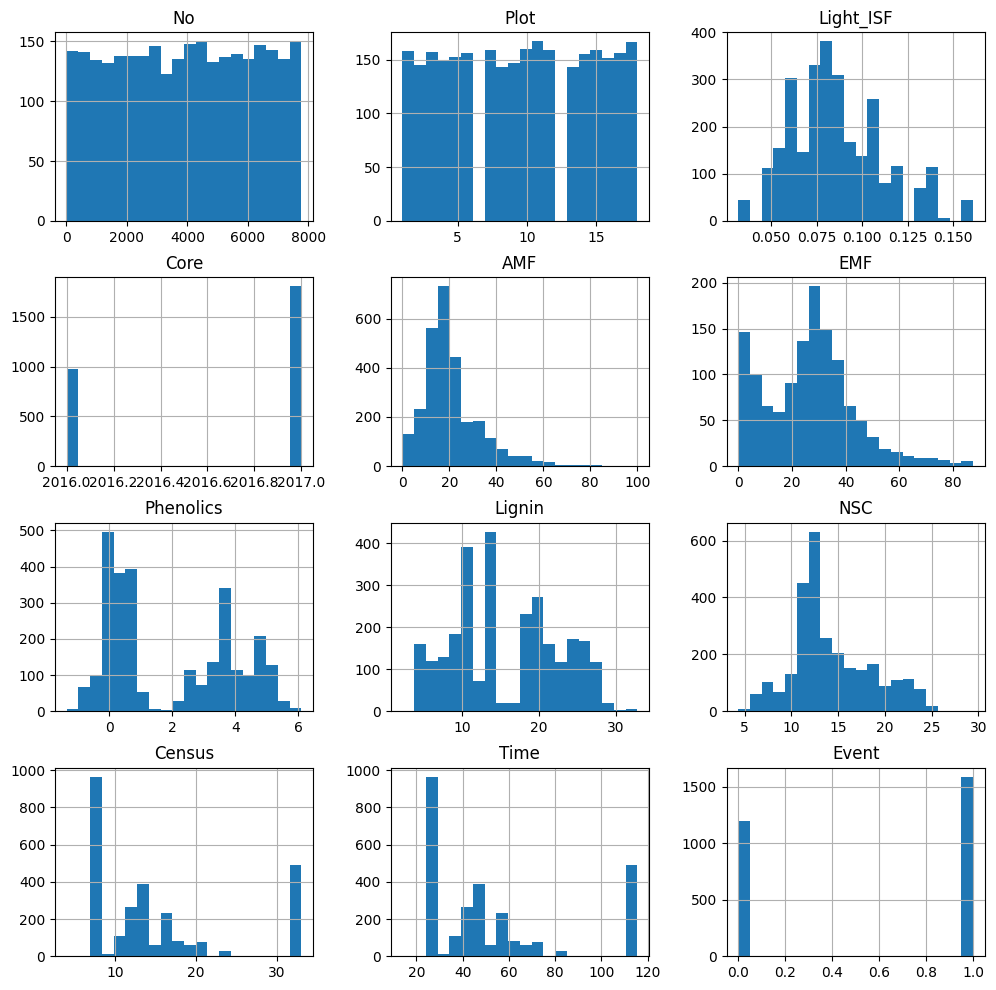

In [ ]:
numerical_data.hist(figsize=(12,12),bins=20)


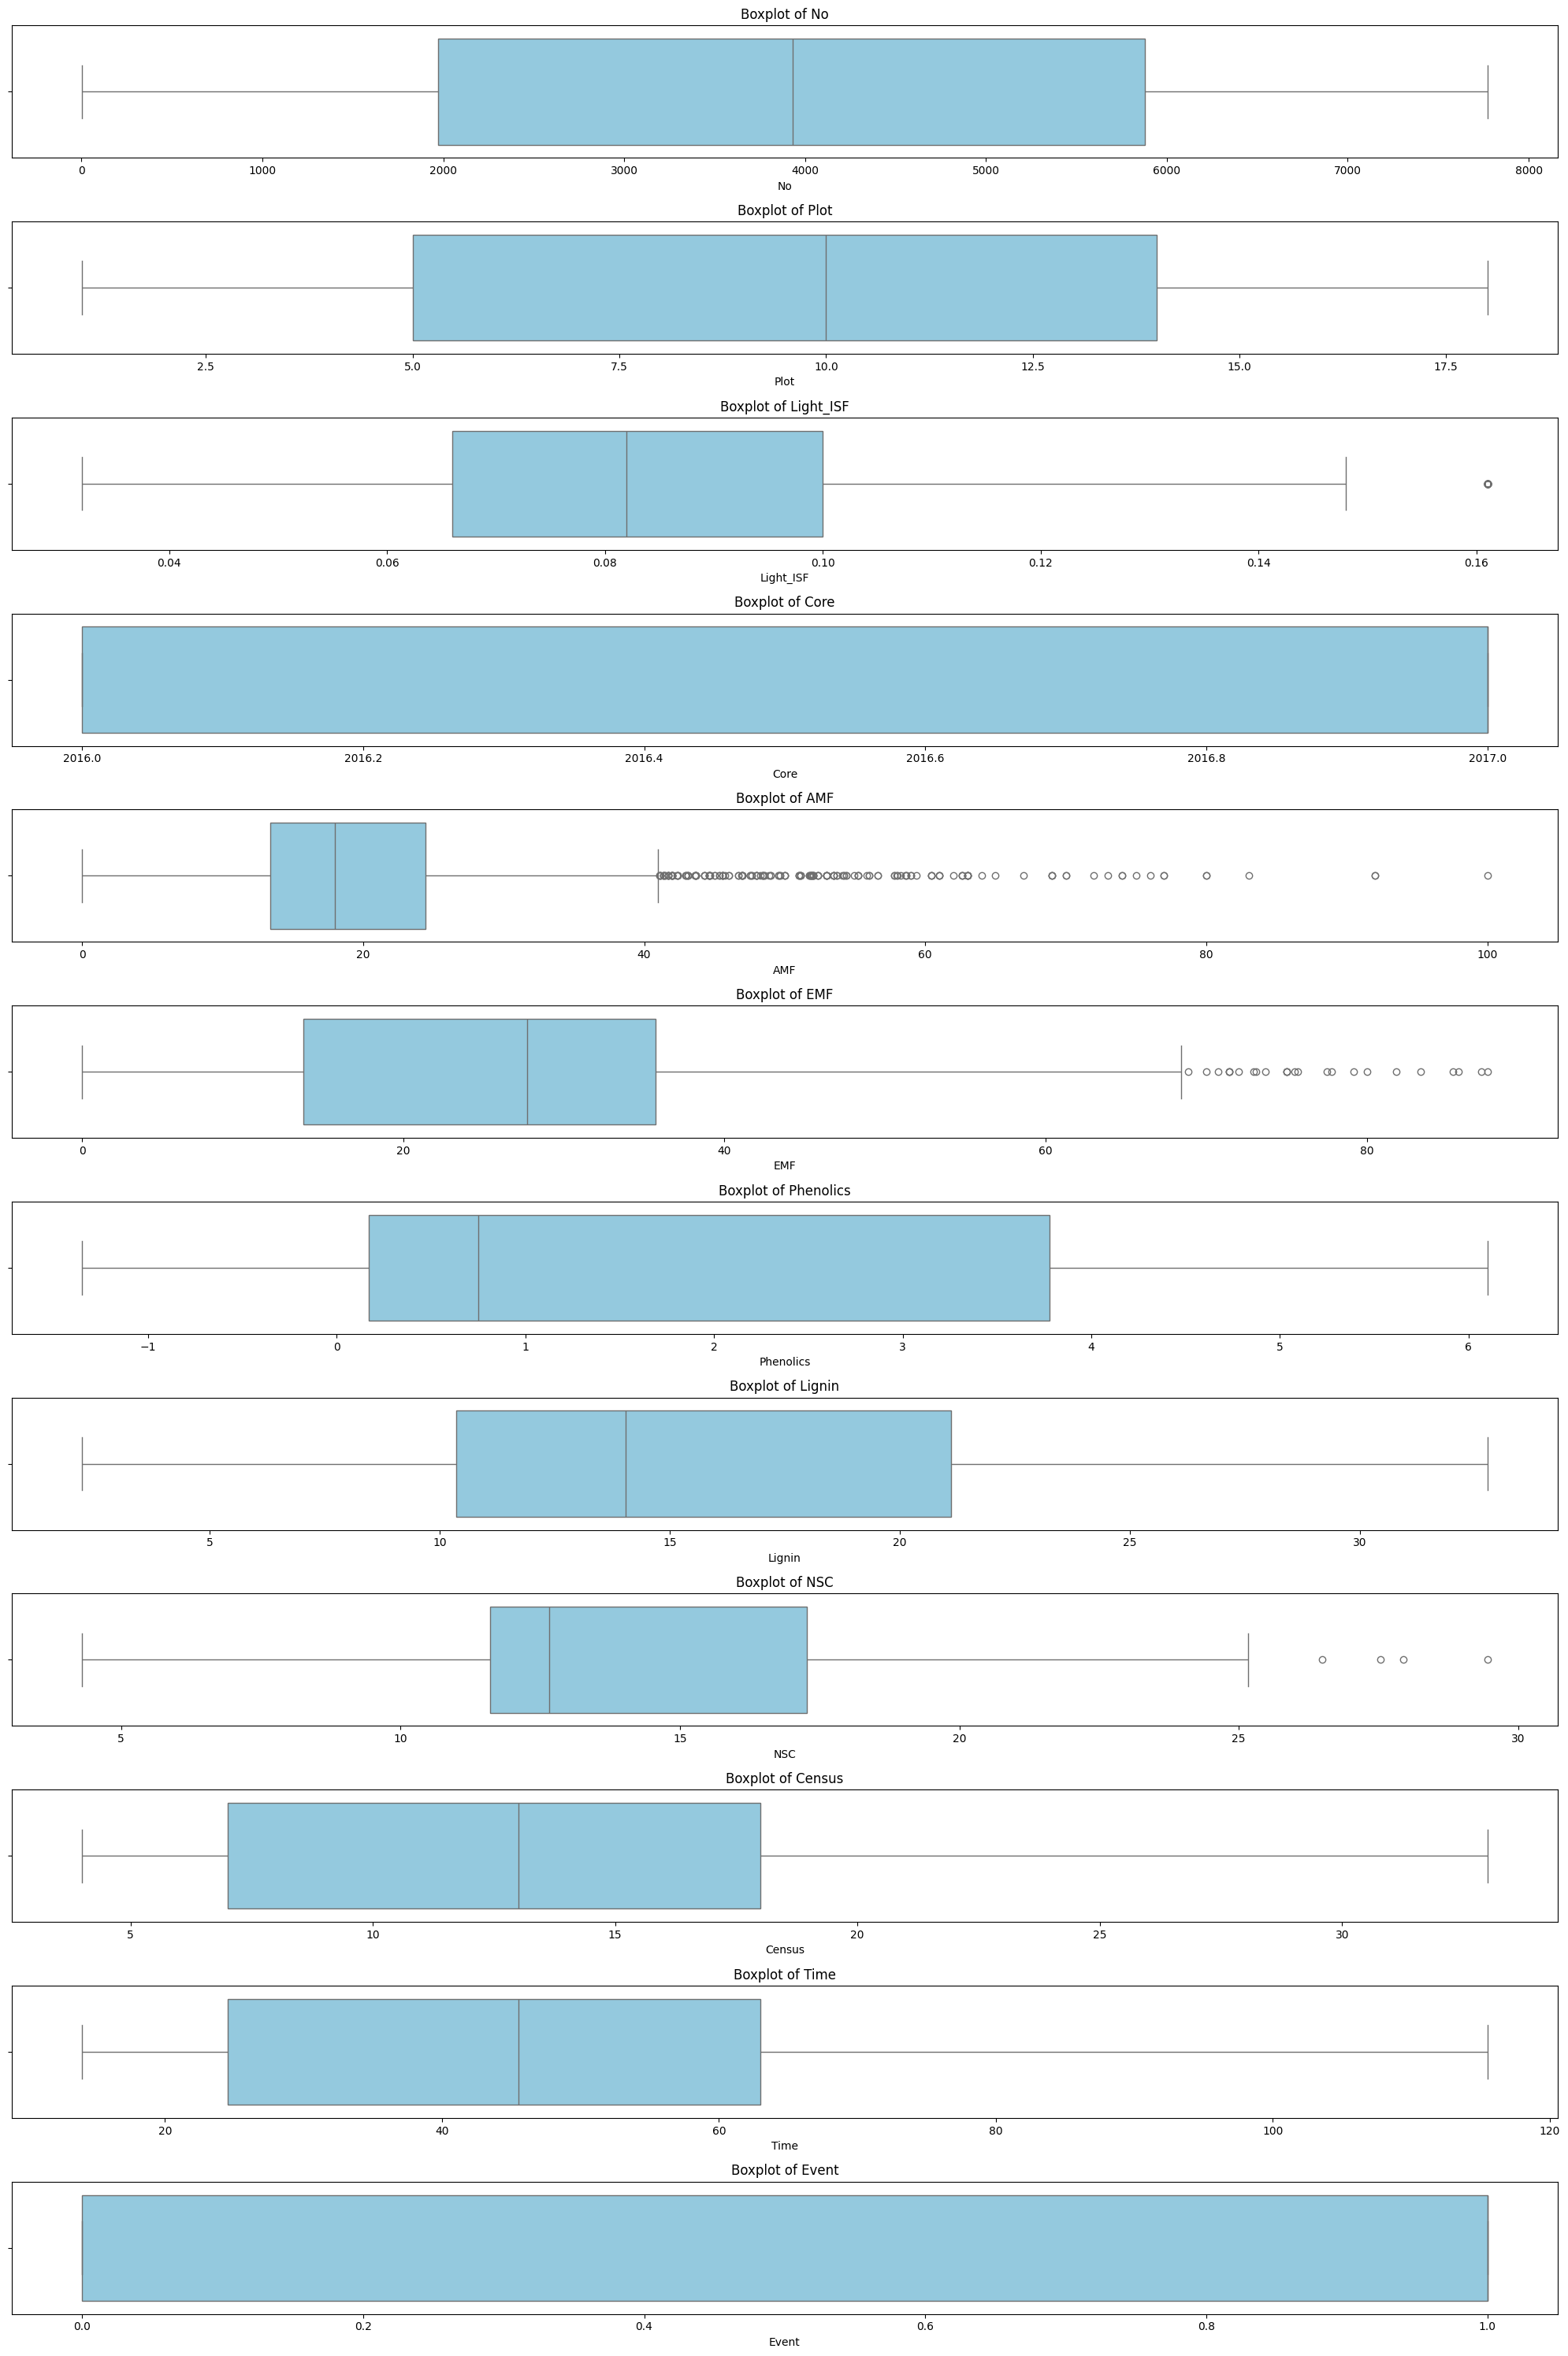

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numerical columns for boxplot analysis
numeric_cols = numerical_data.columns

# Set up the figure
plt.figure(figsize=(20, 30))

# Plot boxplots for each numerical feature including the target variable 'OUTCOME'
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(len(numeric_cols), 1, i)
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Boxplot of {col}', fontsize=12)
    plt.tight_layout()

plt.show()

UNIQUE FEATURES

In [ ]:
numerical_data.nunique()

,0
No,2783
Plot,18
Light_ISF,53
Core,2
AMF,924
EMF,682
Phenolics,494
Lignin,1095
NSC,998
Census,22


In [ ]:
df.shape

(2783, 24)

MISSING VALUES

In [ ]:
df.isnull().sum()

,0
No,0
Plot,0
Subplot,0
Species,0
Light_ISF,0
Light_Cat,0
Core,0
Soil,0
Adult,0
Sterile,0


CATEGORICAL FEATURES

No of unique values in each categorical feature

In [ ]:
# unique values counts
unique_counts=categorical_data.nunique()
print(unique_counts)

Subplot         5
Species         4
Light_Cat       3
Soil            7
Adult          36
Sterile         2
Conspecific     3
Myco            2
SoilMyco        3
PlantDate      19
Harvest         1
Alive           1
dtype: int64


Barplot of unique value counts in every categorical features

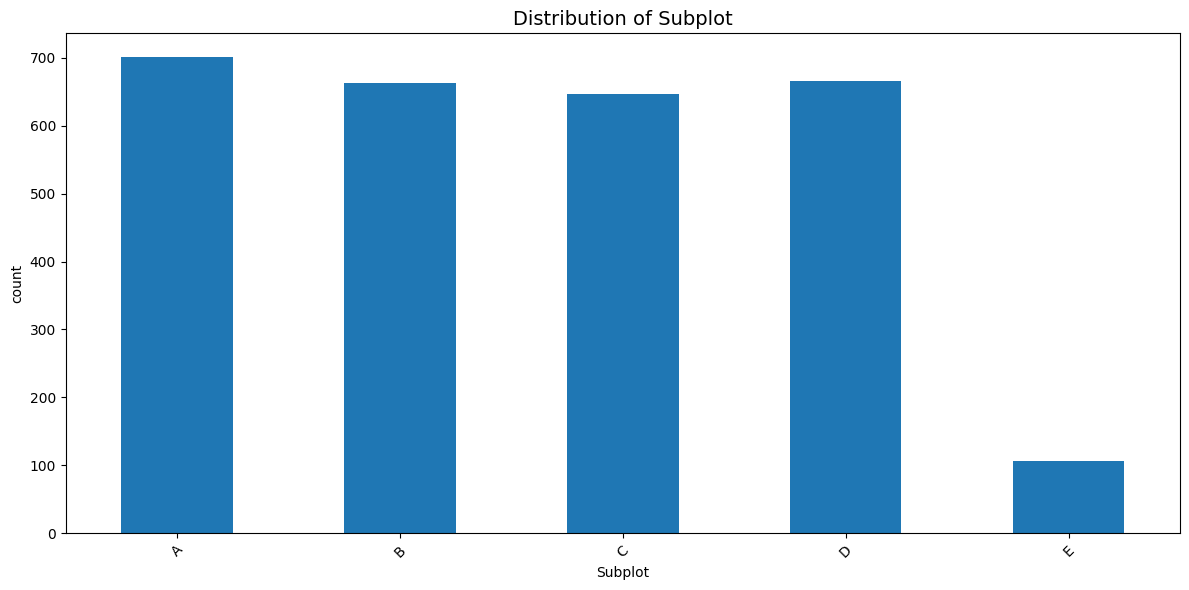

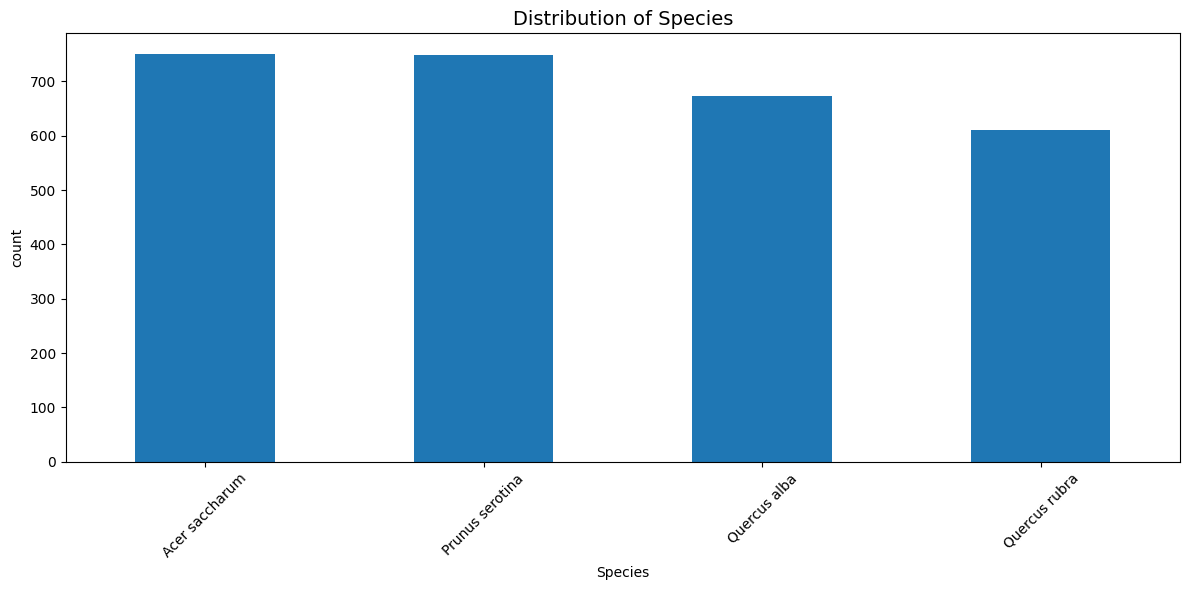

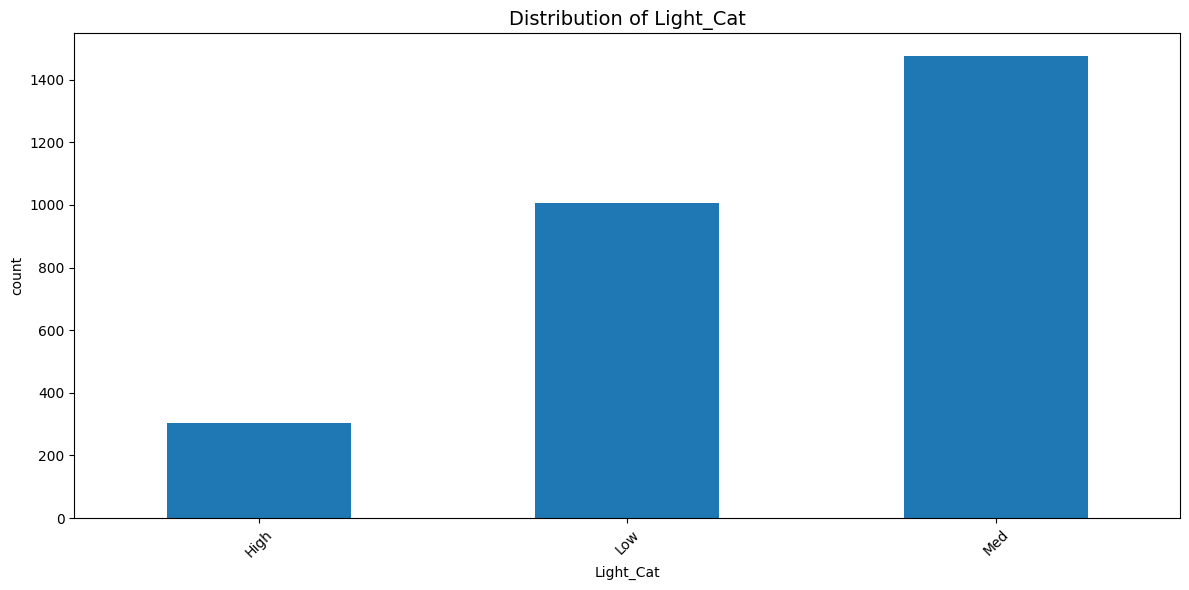

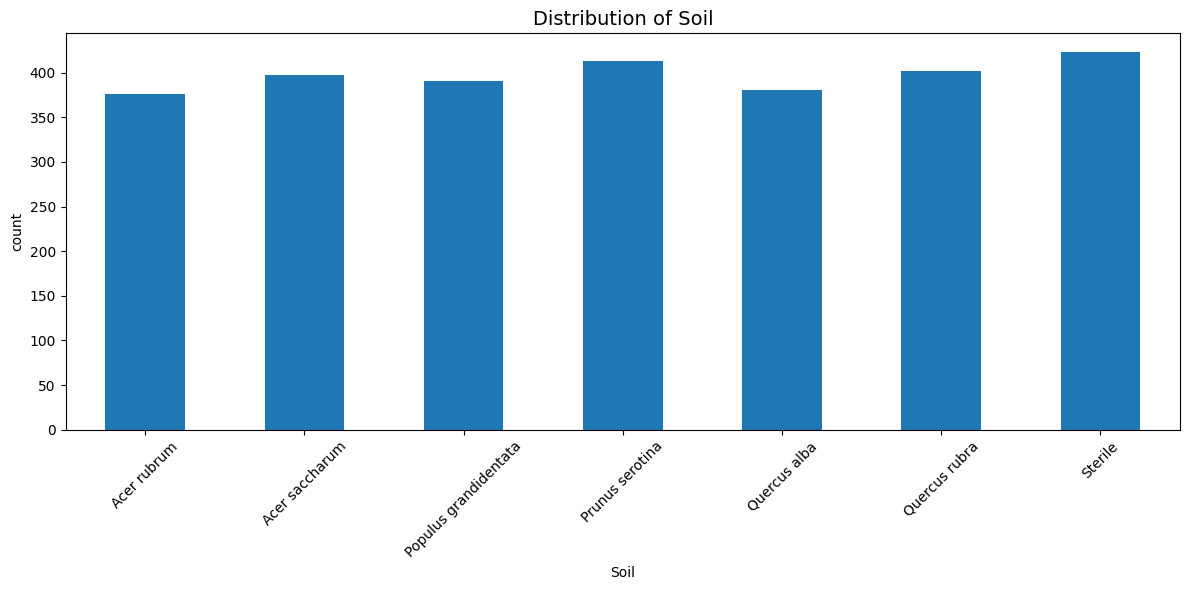

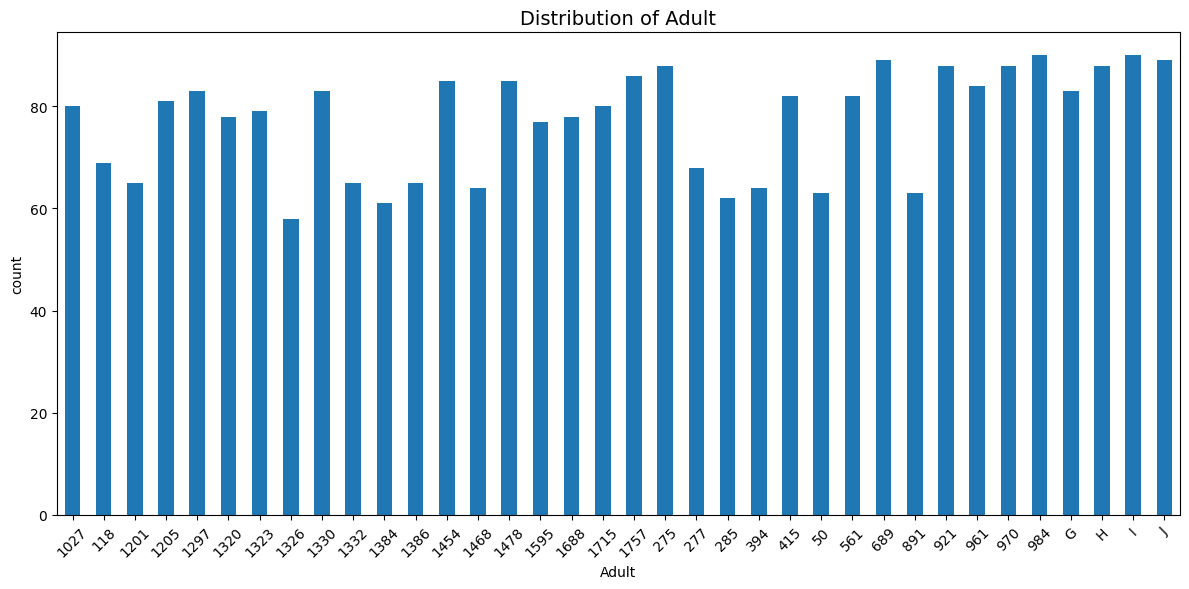

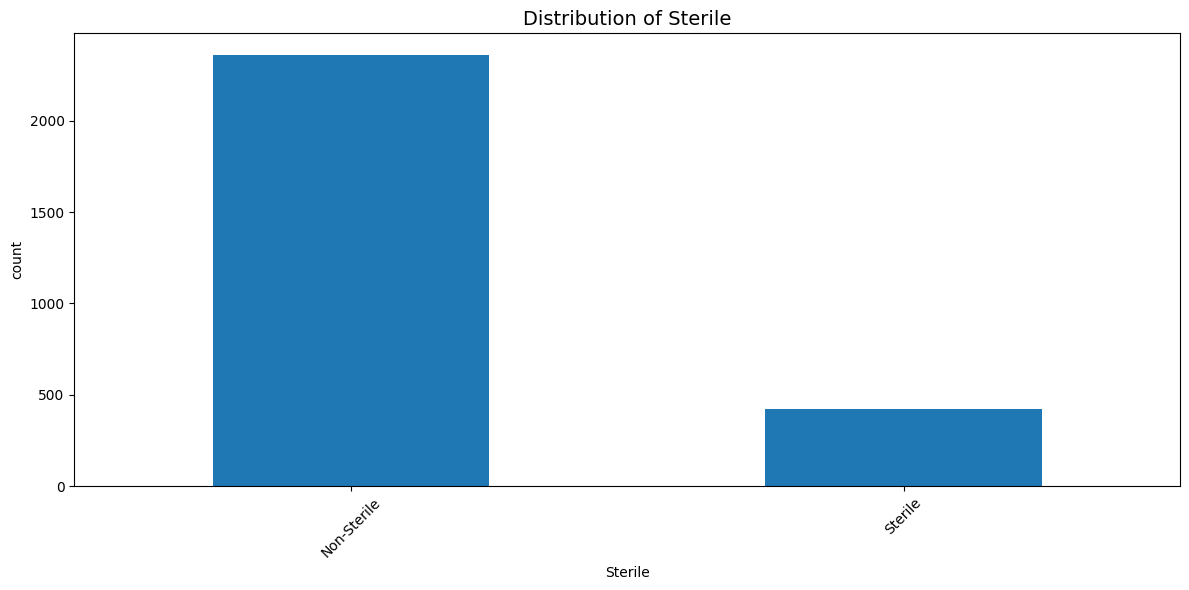

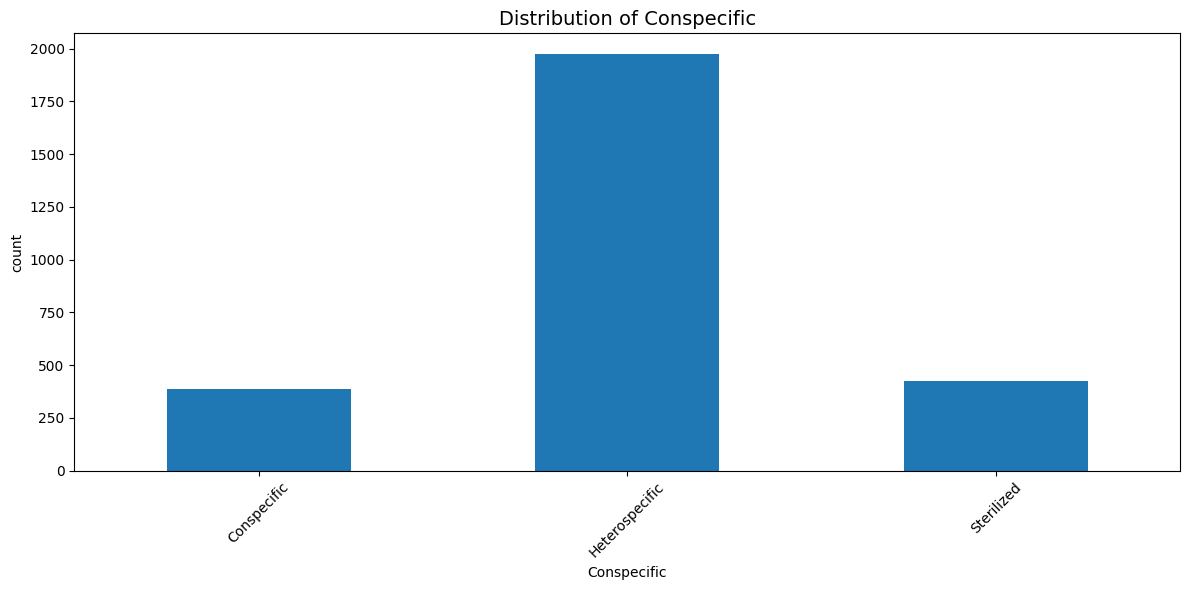

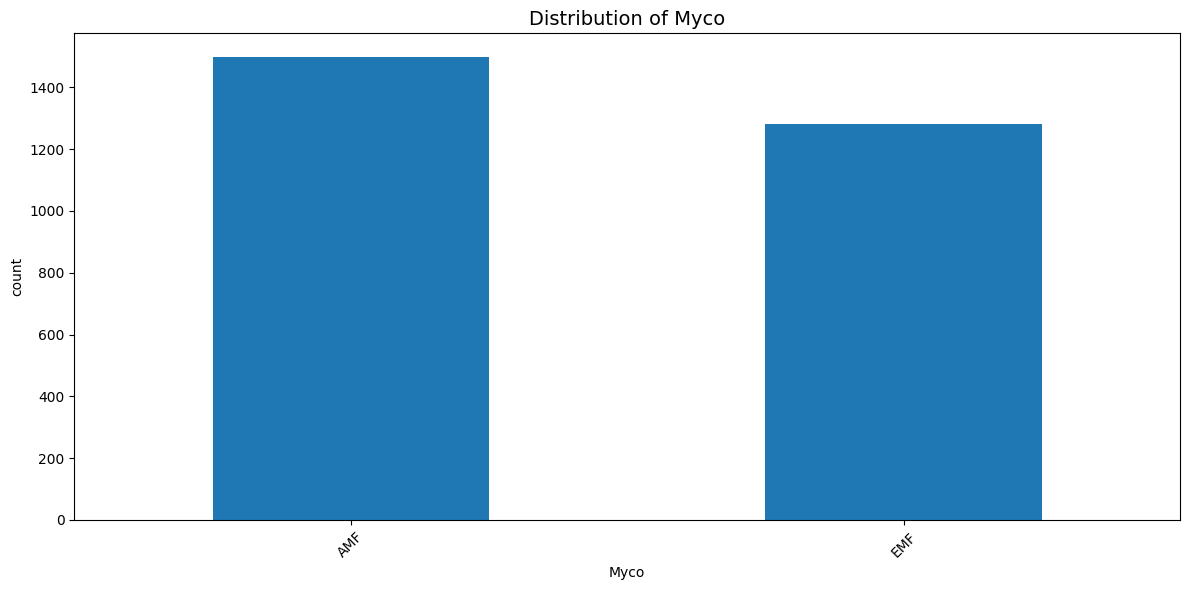

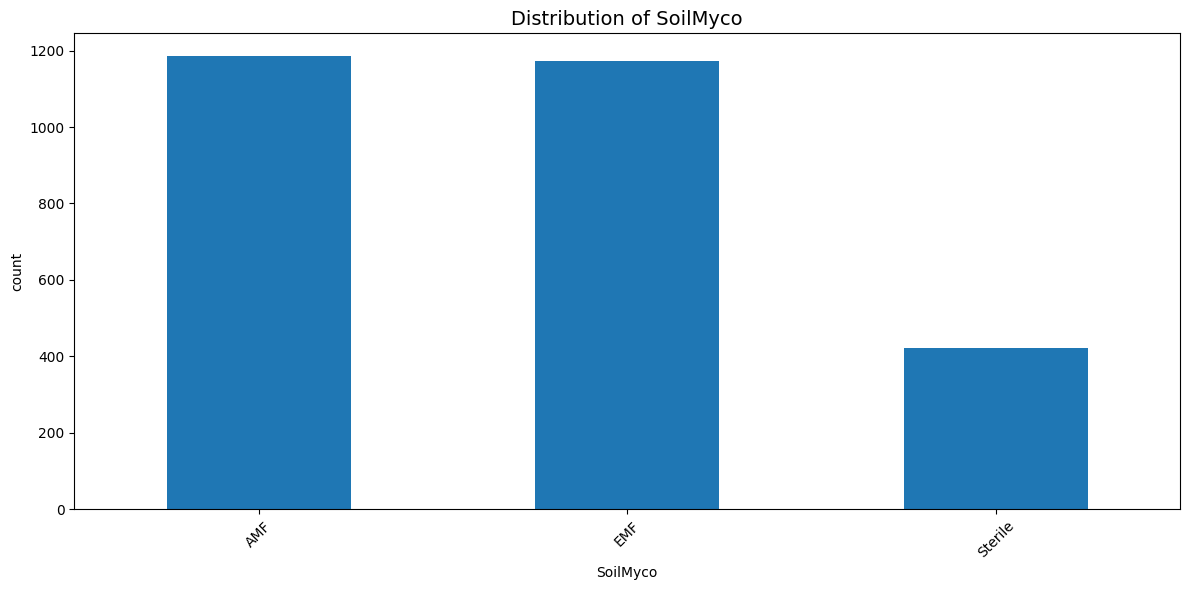

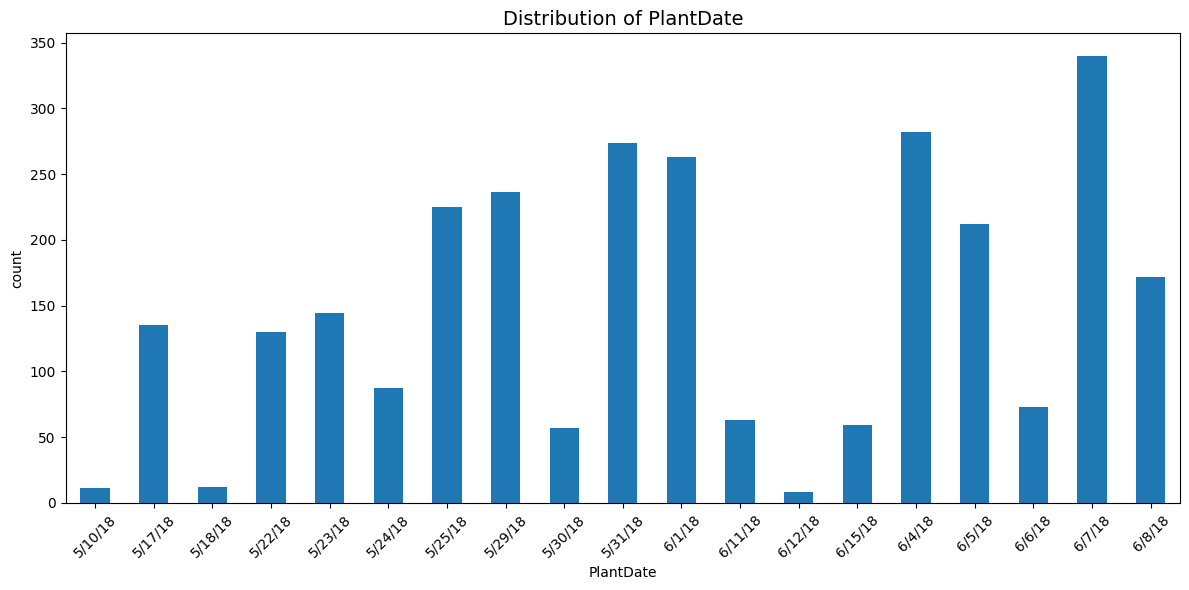

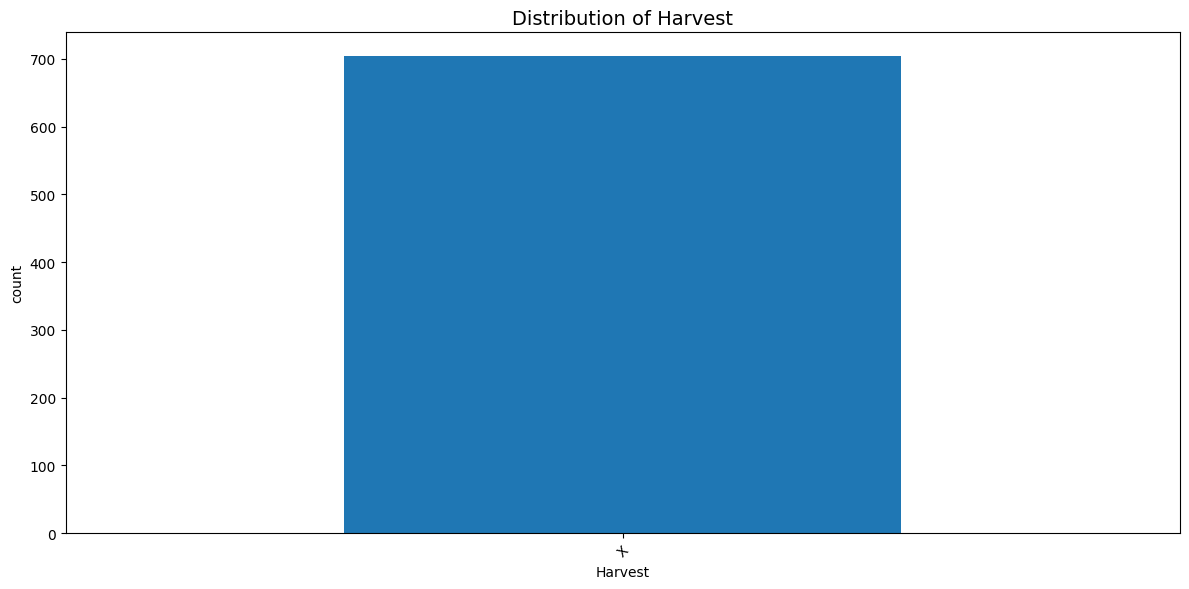

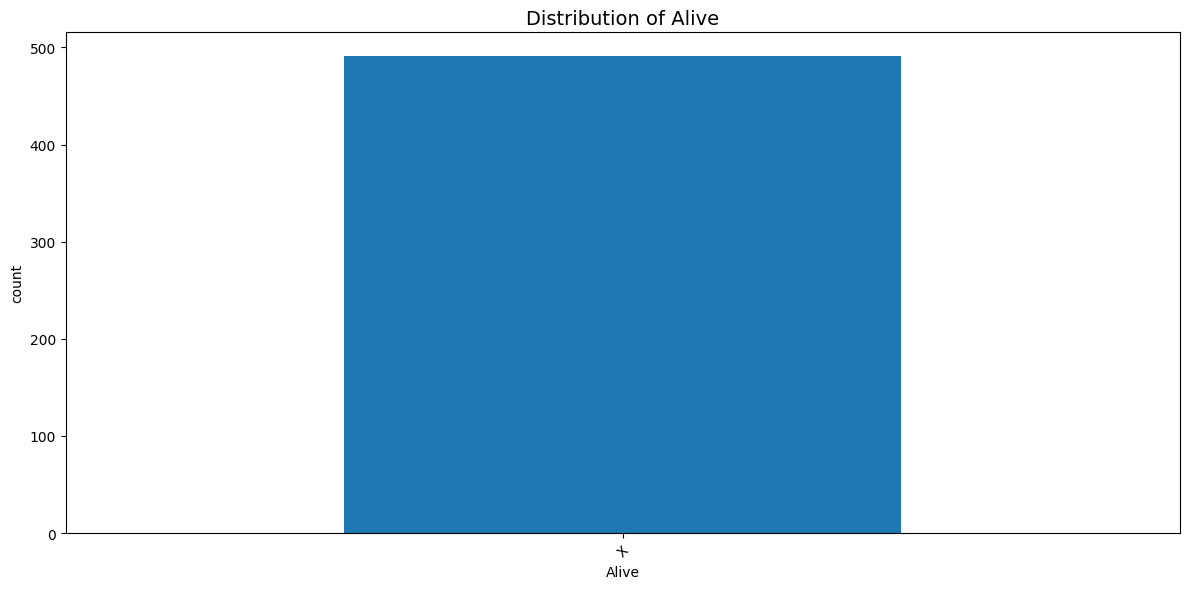

In [ ]:
for col in categorical_features:
    plt.figure(figsize=(12,6))
    plt.title(f'Distribution of {col}', fontsize=14)

    categorical_data[col].value_counts().sort_index().plot(
        kind='bar',
        rot=45,
        xlabel=col,
        ylabel='count'
    )

    plt.tight_layout()
    plt.show()


Correlation Analysis

Correlation matrix of whole dataset

In [ ]:
# Calculate the correlation matrix
correlation_matrix = numerical_data.corr()
correlation_matrix

,No,Plot,Light_ISF,Core,AMF,EMF,Phenolics,Lignin,NSC,Census,Time,Event
No,1.000000,0.998450,0.250086,0.040238,0.082042,0.164707,0.038217,-0.008797,0.026681,-0.062410,-0.062410,-0.070230
Plot,0.998450,1.000000,0.248232,0.037724,0.083960,0.164957,0.038924,-0.009677,0.027051,-0.061303,-0.061303,-0.070711
Light_ISF,0.250086,0.248232,1.000000,0.049650,0.099120,0.163202,0.098531,0.081305,0.227706,0.026203,0.026203,-0.048473
Core,0.040238,0.037724,0.049650,1.000000,-0.056579,-0.140301,0.051929,0.088418,0.054315,0.048183,0.048183,-0.052738
AMF,0.082042,0.083960,0.099120,-0.056579,1.000000,0.264975,-0.121295,-0.304034,-0.181600,-0.090019,-0.090019,0.134544
EMF,0.164707,0.164957,0.163202,-0.140301,0.264975,1.000000,0.359696,0.055293,0.117529,0.001533,0.001533,-0.037480
Phenolics,0.038217,0.038924,0.098531,0.051929,-0.121295,0.359696,1.000000,0.768149,0.791244,0.379782,0.379782,-0.575633
Lignin,-0.008797,-0.009677,0.081305,0.088418,-0.304034,0.055293,0.768149,1.000000,0.546625,0.293374,0.293374,-0.519645
NSC,0.026681,0.027051,0.227706,0.054315,-0.181600,0.117529,0.791244,0.546625,1.000000,0.368411,0.368411,-0.410076
Census,-0.062410,-0.061303,0.026203,0.048183,-0.090019,0.001533,0.379782,0.293374,0.368411,1.000000,1.000000,-0.232227


Correlation Heatmap plot of whole dataset

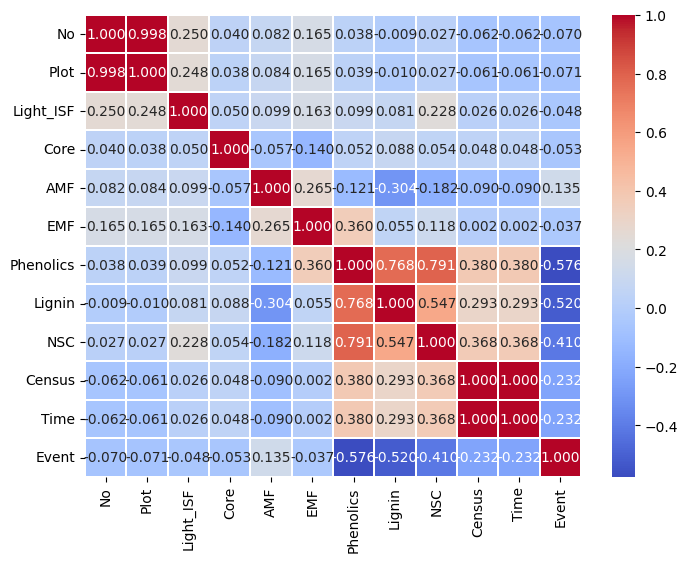

In [ ]:
# Plotting the heatmap for correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.3)
plt.show()

In [ ]:
# Calculate the correlation matrix
if df['Sterile'].dtype == 'object':
    df['Sterile'] = df['Sterile'].map({'Sterile': 1, 'Non-Sterile': 0})
    print(df['Sterile'].value_counts())
# Check for nulls
print(df['Sterile'].isnull().sum())

numerical_data= df.select_dtypes(include=['int64', 'float64'])
numerical_data['Sterile'] = df['Sterile']

correlation_matrix = numerical_data.corr()
print(correlation_matrix)


Sterile
0    2360
1     423
Name: count, dtype: int64
0
                 No      Plot  Light_ISF      Core   Sterile       AMF  \
No         1.000000  0.998450   0.250086  0.040238 -0.010214  0.082042   
Plot       0.998450  1.000000   0.248232  0.037724 -0.010690  0.083960   
Light_ISF  0.250086  0.248232   1.000000  0.049650 -0.011713  0.099120   
Core       0.040238  0.037724   0.049650  1.000000  0.103794 -0.056579   
Sterile   -0.010214 -0.010690  -0.011713  0.103794  1.000000 -0.384148   
AMF        0.082042  0.083960   0.099120 -0.056579 -0.384148  1.000000   
EMF        0.164707  0.164957   0.163202 -0.140301 -0.550586  0.264975   
Phenolics  0.038217  0.038924   0.098531  0.051929 -0.068993 -0.121295   
Lignin    -0.008797 -0.009677   0.081305  0.088418 -0.000716 -0.304034   
NSC        0.026681  0.027051   0.227706  0.054315 -0.038814 -0.181600   
Census    -0.062410 -0.061303   0.026203  0.048183  0.036768 -0.090019   
Time      -0.062410 -0.061303   0.026203  0.048183  0.03

Correlation plot between numerical features and target

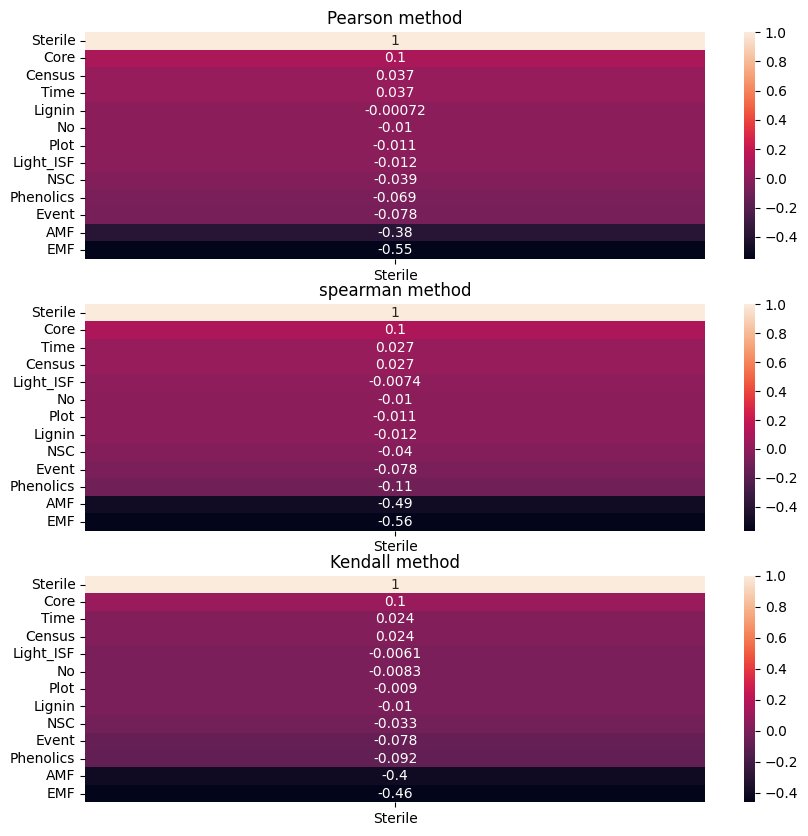

In [ ]:
fig, ax = plt.subplots(3,1, figsize=(10, 10))
## Correlation coefficient using different methods
corr1 = numerical_data.corr('pearson')[['Sterile']].sort_values(by='Sterile', ascending=False)
corr2 = numerical_data.corr('spearman')[['Sterile']].sort_values(by='Sterile', ascending=False)
corr3 = numerical_data.corr('kendall')[['Sterile']].sort_values(by='Sterile', ascending=False)

#setting titles for each plot
ax[0].set_title('Pearson method')
ax[1].set_title('spearman method')
ax[2].set_title('Kendall method')

## Generating heatmaps of each methods
sns.heatmap(corr1, ax=ax[0], annot=True)
sns.heatmap(corr2, ax=ax[1], annot=True)
sns.heatmap(corr3, ax=ax[2], annot=True)

plt.show()

Check imbalance in the data
We have classification problem so we need to check the balance of the given data.

In [ ]:
# Check Imbalance in data

# group instances based on the classes in OUTCOME variable
class_counts = df.groupby("Sterile").size()

columns = ['Sterile', 'count', 'percentage']
outcome = [0, 1]
count = []
percentage = []

# total rows in dataset
total = len(df)

# Calculate the percentage of each value of the OUTCOME variable from total
for val in outcome:
    cnt = class_counts[val]
    count.append(cnt)
    percent = (cnt / total) * 100
    percentage.append(percent)

# Convert the calculated values into a dataframe
imbalance_df = pd.DataFrame(list(zip(outcome, count, percentage)), columns=columns)
imbalance_df


,Sterile,count,percentage
0,0,2360,84.800575
1,1,423,15.199425


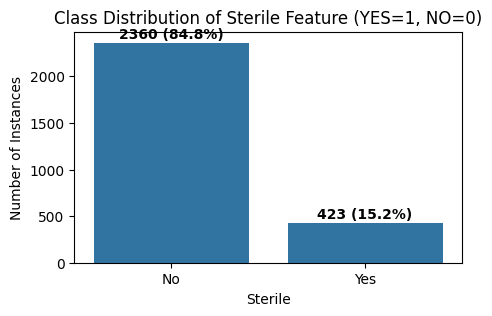

In [ ]:
plt.figure(figsize=(5,3))
ax = sns.countplot(data=df, x='Sterile')

# Add title and labels
plt.title("Class Distribution of Sterile Feature (YES=1, NO=0)")
plt.xlabel("Sterile")
plt.ylabel("Number of Instances")
plt.xticks(ticks=[0,1], labels=['No', 'Yes'])

# Add counts and percentages above bars with better spacing
total = len(df)
for p in ax.patches:
    count = int(p.get_height())
    percentage = 100 * count / total
    ax.annotate(f'{count} ({percentage:.1f}%)',
                (p.get_x() + p.get_width() / 2., p.get_height() + 50),  # shift upward
                ha='center', fontsize=10, color='black', weight='bold')

plt.show()


Density plots of numerical features

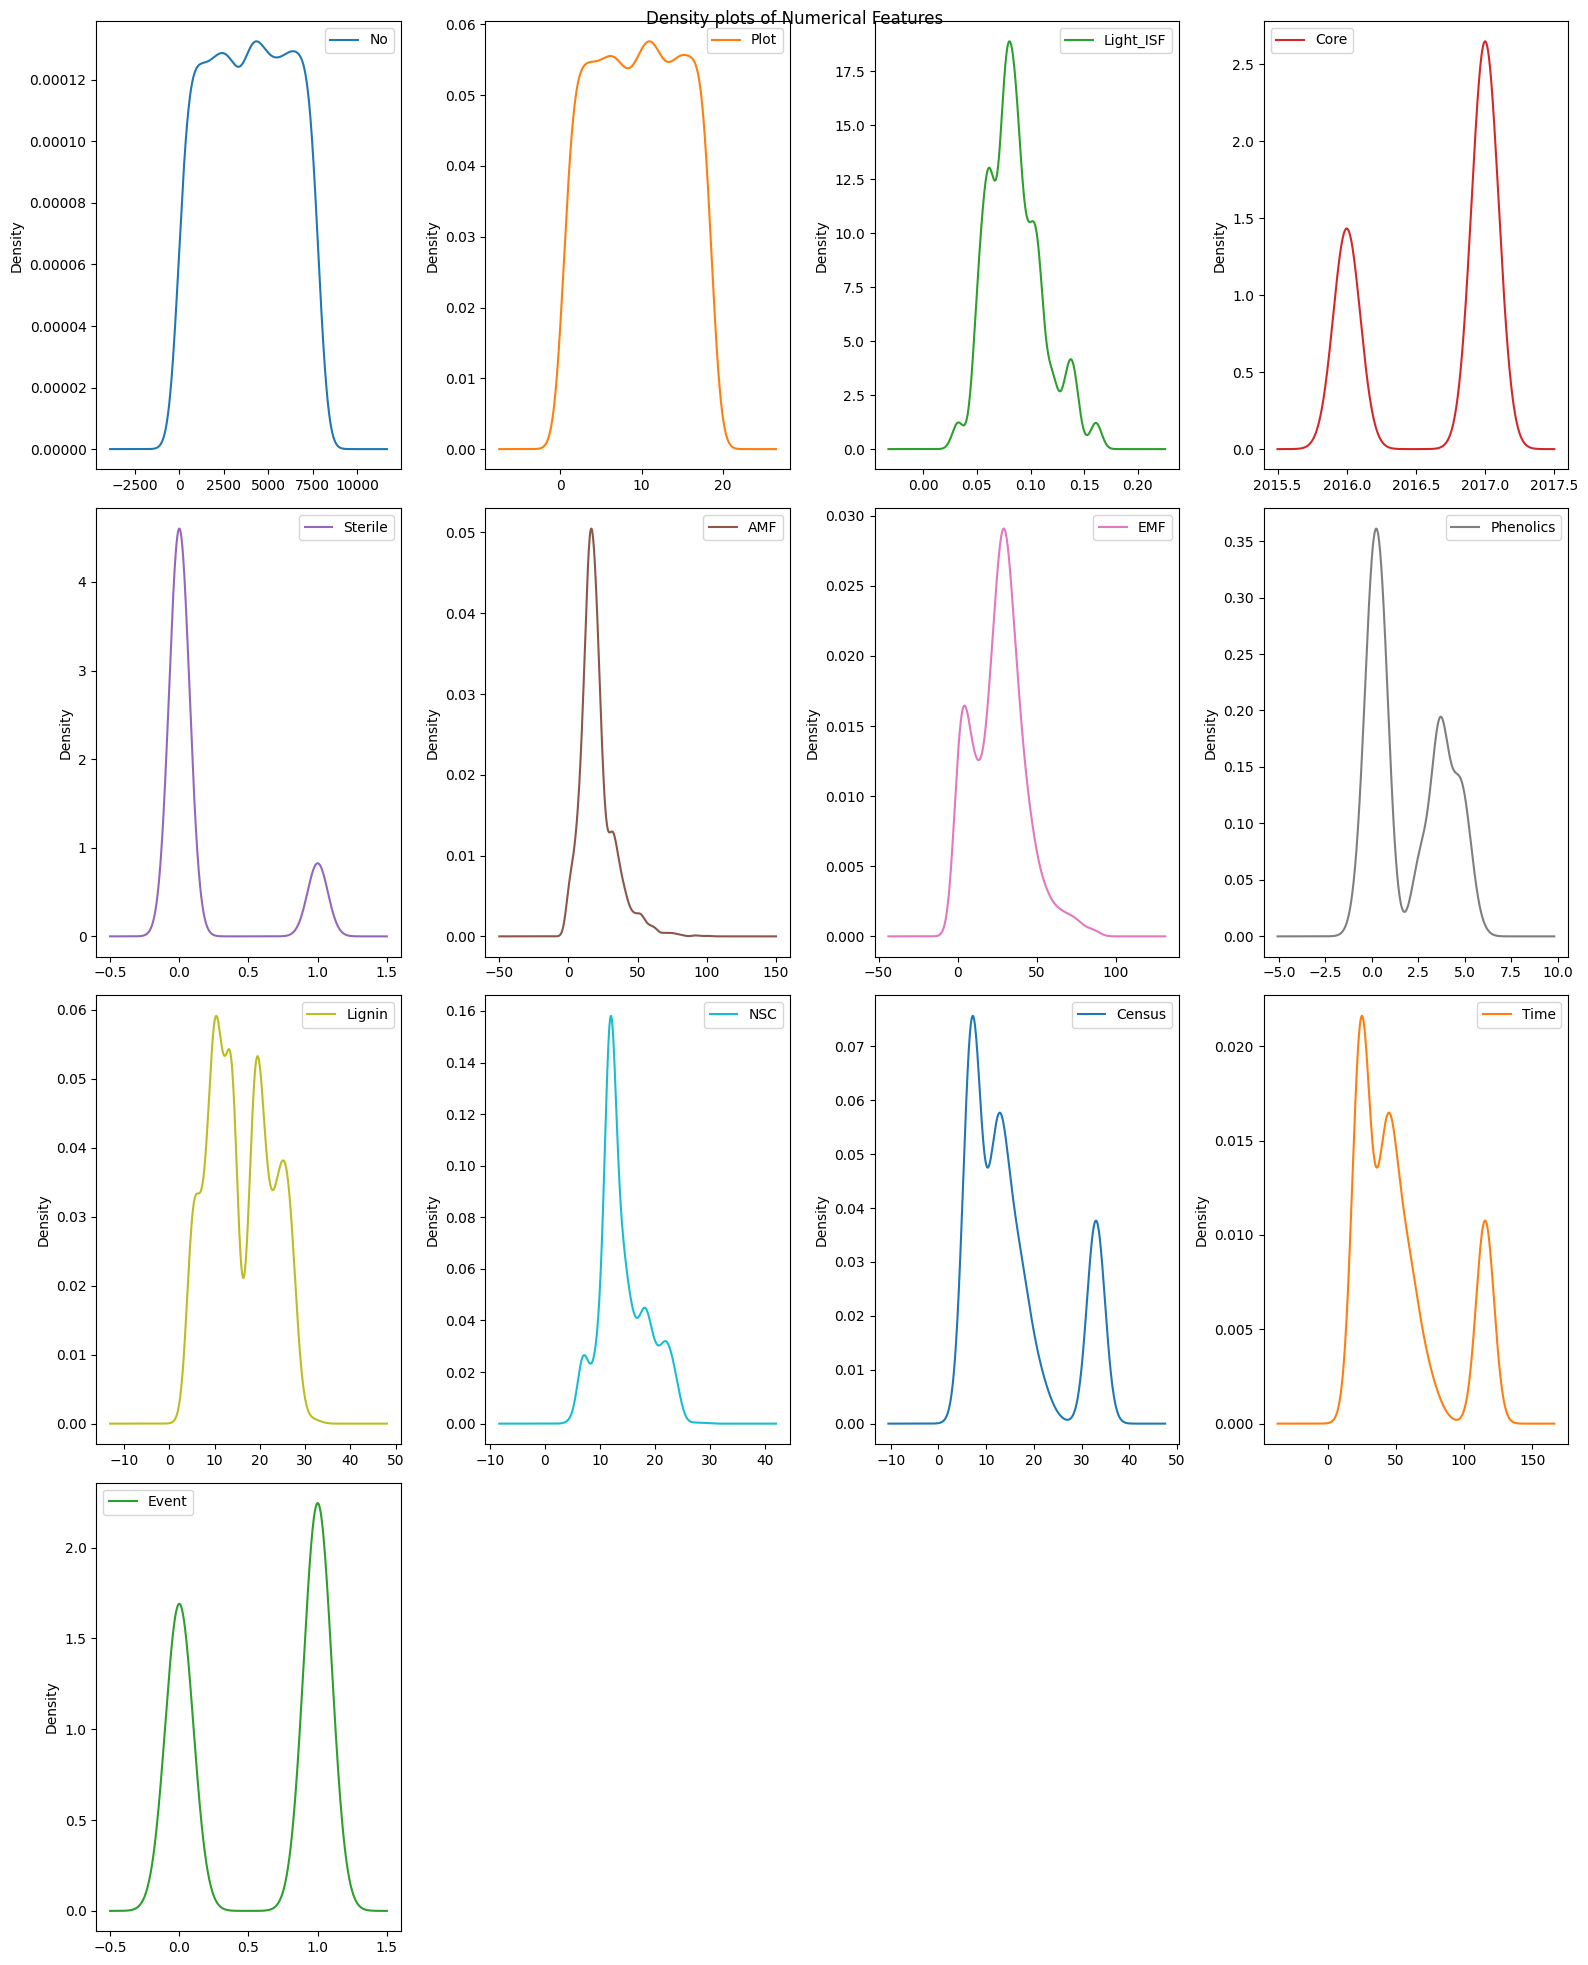

In [ ]:

numerical_data.plot(kind='density', subplots=True, layout=(-1, 4), figsize=(16, 20), sharex=False, title="Density plots of Numerical Features")
plt.tight_layout()
plt.show()


**DATA PRE-PROCESSING**

In [ ]:
print(f"features (excluding the target-Sterile): {df.shape[1]-1}")
print(f"data points: {df.shape[0]}")


features (excluding the target-Sterile): 23
data points: 2783


In [ ]:
print("Shape before dropping",df.shape)
df=df.drop(['Harvest'], axis=1)
print("Shape after dropping colums",df.shape)

Shape before dropping (2783, 24)
Shape after dropping colums (2783, 23)


In [ ]:
print("Shape before dropping",df.shape)
df=df.drop(['Alive'], axis=1)
print("Shape after dropping colums",df.shape)

Shape before dropping (2783, 23)
Shape after dropping colums (2783, 22)


In [ ]:
print("Shape before dropping",df.shape)
df=df.drop(['SoilMyco'], axis=1)
print("Shape after dropping colums",df.shape)

Shape before dropping (2783, 22)
Shape after dropping colums (2783, 21)


In [ ]:
print("Shape before dropping",df.shape)
df=df.drop(['Plot'], axis=1)
print("Shape after dropping colums",df.shape)

Shape before dropping (2783, 21)
Shape after dropping colums (2783, 20)


In [ ]:
print("Shape before dropping",df.shape)
df=df.drop(['Census'], axis=1)
print("Shape after dropping colums",df.shape)

Shape before dropping (2783, 20)
Shape after dropping colums (2783, 19)


In [ ]:
# Find mode of Cospecific
cos_mode = df['Conspecific'].mode()[0]

# Replace "sterilized" in Sterile column with that mode
df['Conspecific'] = df['Conspecific'].replace("Sterilized", cos_mode)

# Check result
print("Mode of Cospecific:", cos_mode)
print(df['Conspecific'].value_counts())


Mode of Cospecific: Heterospecific
Conspecific
Heterospecific    2397
Conspecific        386
Name: count, dtype: int64


In [ ]:

print("Unique values in Adult:\n", df["Adult"].unique())

# Convert to numeric, force errors to NaN
df["Adult"] = pd.to_numeric(df["Adult"], errors="coerce")

# Now non-numeric values (like I, J) become NaN
print("After conversion:\n", df["Adult"].head())

# Impute missing values with mean
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="mean")
df["Adult"] = imputer.fit_transform(df[["Adult"]])

print("After imputation:\n", df["Adult"].head())

Unique values in Adult:
 ['I' '970' 'J' '689' '1332' '891' '1595' '1323' '394' '561' '1478' '1320'
 '1454' '921' '984' '118' '1757' '1384' '1688' '961' '1715' '50' '1468'
 '1201' '1386' '277' '415' '285' '275' '1205' '1330' '1297' '1326' 'H'
 '1027' 'G']
After conversion:
 0      NaN
1    970.0
2      NaN
3      NaN
4    689.0
Name: Adult, dtype: float64
After imputation:
 0    1043.031237
1     970.000000
2    1043.031237
3    1043.031237
4     689.000000
Name: Adult, dtype: float64


In [ ]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="mean")


df['EMF'] = imputer.fit_transform(df[['EMF']])

print("Number of missing values in EMF after imputation:", df['EMF'].isnull().sum())
print(df['EMF'].head())

Number of missing values in EMF after imputation: 0
0    26.47675
1    31.07000
2    28.19000
3    26.47675
4    26.47675
Name: EMF, dtype: float64


In [ ]:
for col in ["EMF"]:
    df[col] = df[col].fillna(df[col].mean())


print("Number of missing values in EMF:", df["EMF"].isnull().sum())


print(df["EMF"].head(10))

print(df["EMF"].describe())


Number of missing values in EMF: 0
0    26.47675
1    31.07000
2    28.19000
3    26.47675
4    26.47675
5    26.47675
6    20.00000
7     0.00000
8    36.18000
9    26.47675
Name: EMF, dtype: float64
count    2783.000000
mean       26.476750
std        11.293735
min         0.000000
25%        26.476750
50%        26.476750
75%        26.476750
max        87.500000
Name: EMF, dtype: float64


In [ ]:
# Convert to datetime
df["PlantDate"] = pd.to_datetime(df["PlantDate"], errors="coerce")


df["PlantYear"] = df["PlantDate"].dt.year
df["PlantMonth"] = df["PlantDate"].dt.month
df["PlantDay"] = df["PlantDate"].dt.day


df["PlantSeason"] = df["PlantDate"].dt.month % 12 // 3 + 1

# Drop the original date column
df = df.drop("PlantDate", axis=1)


/tmp/ipython-input-2438347822.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["PlantDate"] = pd.to_datetime(df["PlantDate"], errors="coerce")


DATA SPLITTING

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

X = df.drop("Sterile", axis=1)
y = df["Sterile"]

# Stratified train-test split (70-30)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

print("training",X_train.shape)
print('testing',X_test.shape)

training (1948, 21)
testing (835, 21)


In [ ]:
print("y_train distribution:\n", y_train.value_counts())
print("y_test distribution:\n", y_test.value_counts())


y_train distribution:
 Sterile
0    1652
1     296
Name: count, dtype: int64
y_test distribution:
 Sterile
0    708
1    127
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import StandardScaler

num_cols = X.select_dtypes(include=np.number).columns
scaler = StandardScaler()
X[num_cols] = scaler.fit_transform(X[num_cols])

In [ ]:
# Check first few rows of scaled numeric features
X[num_cols].head()


,No,Light_ISF,Core,Adult,AMF,EMF,Phenolics,Lignin,NSC,Time,Event,PlantYear,PlantMonth,PlantDay,PlantSeason
0,-1.681460,0.791680,0.735510,0.000000,0.117566,0.000000,-1.265864,-0.280272,-0.481592,-1.231007,0.867752,0.0,0.943729,-0.377715,0.943729
1,-1.732500,0.791680,0.735510,-0.160944,-0.384572,0.406781,1.653676,0.702262,1.179840,1.933236,-1.152403,0.0,-1.059626,0.929260,-1.059626
2,-1.732056,0.791680,0.735510,0.000000,0.316634,0.151726,0.724501,1.324829,0.183911,0.296558,0.867752,0.0,-1.059626,1.489392,-1.059626
3,-0.484448,-0.222634,-1.359601,0.000000,0.136254,0.000000,-1.342026,-0.216835,-0.432726,-1.231007,0.867752,0.0,0.943729,-0.377715,0.943729
4,0.783134,-1.002875,0.735510,-0.780203,0.048502,0.000000,-1.276019,-0.724330,-0.702651,-1.231007,0.867752,0.0,0.943729,-0.377715,0.943729


In [ ]:
X[num_cols].agg(["mean", "std"]).T


,mean,std
No,-4.085046e-17,1.00018
Light_ISF,1.991460e-16,1.00018
Core,1.500623e-13,1.00018
Adult,1.276577e-17,1.00018
AMF,6.127569e-17,1.00018
EMF,8.170093e-17,1.00018
Phenolics,4.085046e-17,1.00018
Lignin,-1.225514e-16,1.00018
NSC,4.085046e-17,1.00018
Time,1.021262e-16,1.00018


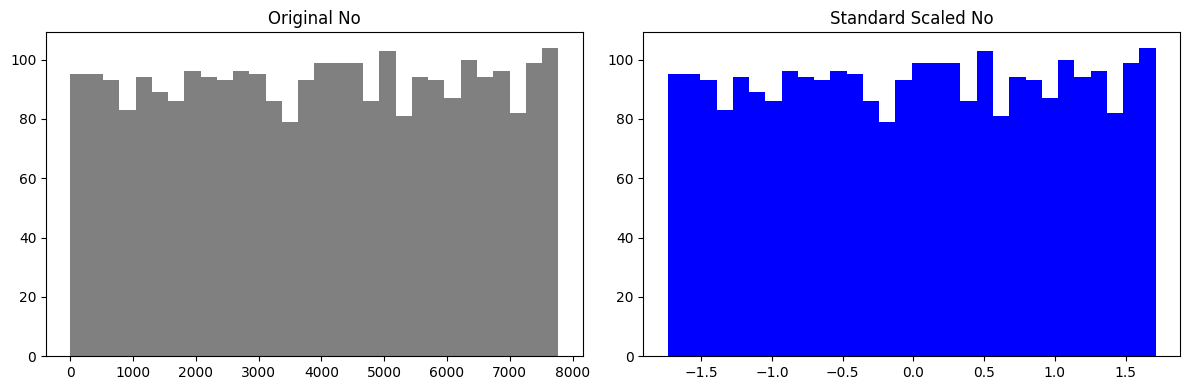

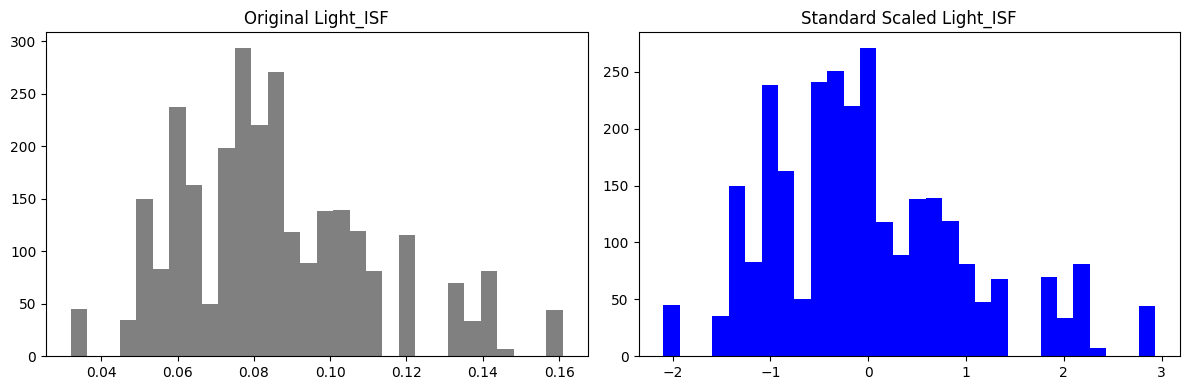

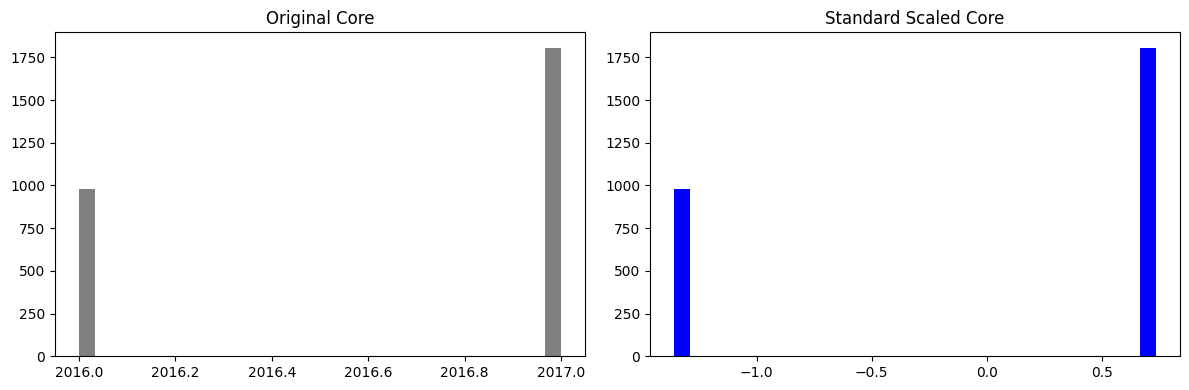

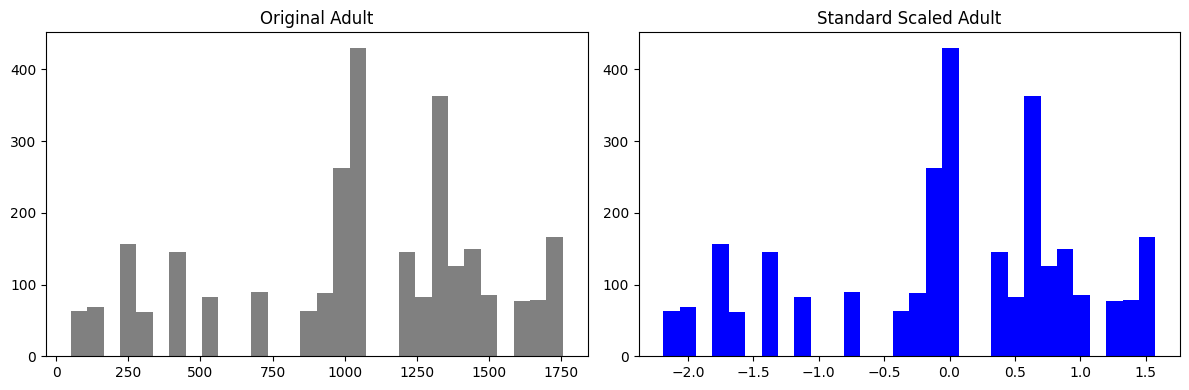

In [ ]:
import matplotlib.pyplot as plt


for col in num_cols[:4]:
    plt.figure(figsize=(12,4))

    # Original (before scaling)
    plt.subplot(1,2,1)
    plt.hist(df[col], bins=30, color="gray")
    plt.title(f"Original {col}")

    # Scaled (after StandardScaler)
    plt.subplot(1,2,2)
    plt.hist(X[col], bins=30, color="blue")
    plt.title(f"Standard Scaled {col}")

    plt.tight_layout()
    plt.show()


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import pandas as pd


#  Encode Light_Cat

for dataset in [X_train, X_test]:
    dataset["Light_Cat"] = dataset["Light_Cat"].map({"Low": 0, "Med": 1, "High": 2})


# Auto-detect categorical and numerical columns

categorical_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

# Define transformers with imputation

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),     # Fill NaN with mean
    ('scaler', RobustScaler())                       # Scale
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),  # Fill NaN with mode
    ('onehot', OneHotEncoder(drop="first", handle_unknown="ignore"))  # Encode
])


# Build ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)


# 7. Fit + transform

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

print("Train shape:", X_train_scaled.shape)
print("Test shape:", X_test_scaled.shape)


Categorical columns: ['Subplot', 'Species', 'Soil', 'Conspecific', 'Myco']
Numerical columns: ['No', 'Light_ISF', 'Light_Cat', 'Core', 'Adult', 'AMF', 'EMF', 'Phenolics', 'Lignin', 'NSC', 'Time', 'Event']
Train shape: (1948, 27)
Test shape: (835, 27)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import pandas as pd

# Label Encode Light_Cat (ordinal mapping)
for dataset in [X_train, X_test]:
    dataset["Light_Cat"] = dataset["Light_Cat"].map({"Low": 0, "Med": 1, "High": 2})

# Auto-detect categorical and numerical columns
# EXCLUDE Light_Cat from categorical, include it as numerical
categorical_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Ensure Light_Cat is inside numerical columns
if "Light_Cat" not in numerical_cols:
    numerical_cols.append("Light_Cat")
if "Light_Cat" in categorical_cols:
    categorical_cols.remove("Light_Cat")

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

# Define transformers with imputation
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),     # Fill NaN with mean
    ('scaler', RobustScaler())                       # Scale
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),  # Fill NaN with mode
    ('onehot', OneHotEncoder(drop="first", handle_unknown="ignore"))  # Encode other categorical
])

# Build ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

# Fit + transform
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

print("Train shape:", X_train_scaled.shape)
print("Test shape:", X_test_scaled.shape)


Categorical columns: ['Subplot', 'Species', 'Soil', 'Conspecific', 'Myco']
Numerical columns: ['No', 'Light_ISF', 'Light_Cat', 'Core', 'Adult', 'AMF', 'EMF', 'Phenolics', 'Lignin', 'NSC', 'Time', 'Event']
Train shape: (1948, 26)
Test shape: (835, 26)


/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Light_Cat']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Light_Cat']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


In [ ]:
print("NaNs in X_train_scaled:", pd.DataFrame(X_train_scaled).isna().sum().sum())
print("NaNs in X_test_scaled:", pd.DataFrame(X_test_scaled).isna().sum().sum())
print("NaNs in y_train:", y_train.isna().sum())
print("NaNs in y_test:", y_test.isna().sum())


NaNs in X_train_scaled: 0
NaNs in X_test_scaled: 0
NaNs in y_train: 0
NaNs in y_test: 0


**MODEL TRAINING AND TESTING**

In [ ]:
print("Target distribution:\n", df["Sterile"].value_counts())


Target distribution:
 Sterile
0    2360
1     423
Name: count, dtype: int64


In [ ]:
print("y_train distribution:\n", y_train.value_counts())
print("y_test distribution:\n", y_test.value_counts())


y_train distribution:
 Sterile
0    1652
1     296
Name: count, dtype: int64
y_test distribution:
 Sterile
0    708
1    127
Name: count, dtype: int64


In [ ]:
models = {
    "Logistic Regression": LogisticRegression(),
    "Random Forest": RandomForestClassifier(),


    "Neural Network": MLPClassifier(hidden_layer_sizes=(20,), alpha=0.01, max_iter=200, random_state=42),
     "Decision Tree": DecisionTreeClassifier(max_depth=12, min_samples_split=5, random_state=42)
}


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc


In [ ]:
results = {}

for name, model in models.items():
    # Fit model on preprocessed (scaled + encoded) data
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    cm = confusion_matrix(y_test, y_pred)

    # Save results
    results[name] = {
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'confusion_matrix': cm
    }

    # Print results
    print(f"\nModel: {name}")
    print("Accuracy:", acc)
    print("Precision:", prec)
    print("Recall:", rec)
    print("Confusion Matrix:\n", cm)



Model: Logistic Regression
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
Confusion Matrix:
 [[708   0]
 [  0 127]]

Model: Random Forest
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
Confusion Matrix:
 [[708   0]
 [  0 127]]

Model: Neural Network
Accuracy: 0.9976047904191617
Precision: 1.0
Recall: 0.984251968503937
Confusion Matrix:
 [[708   0]
 [  2 125]]

Model: Decision Tree
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
Confusion Matrix:
 [[708   0]
 [  0 127]]


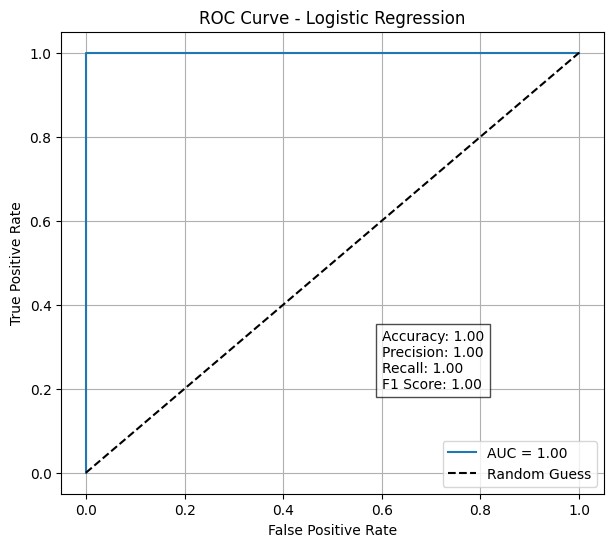

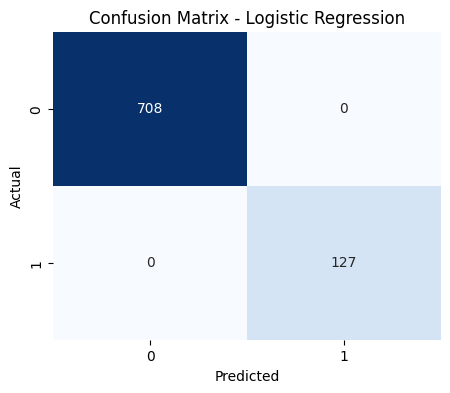

Accuracy for Logistic Regression: 1.0000



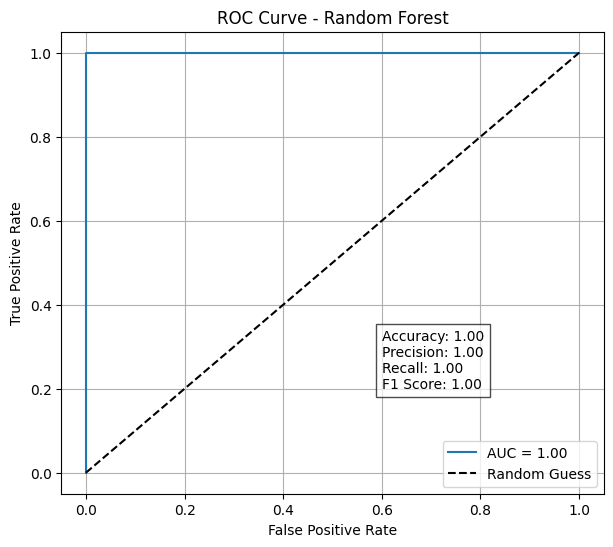

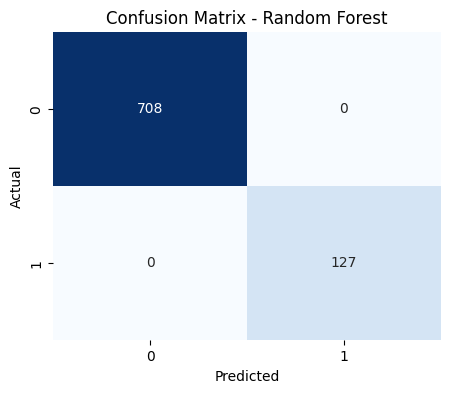

Accuracy for Random Forest: 1.0000



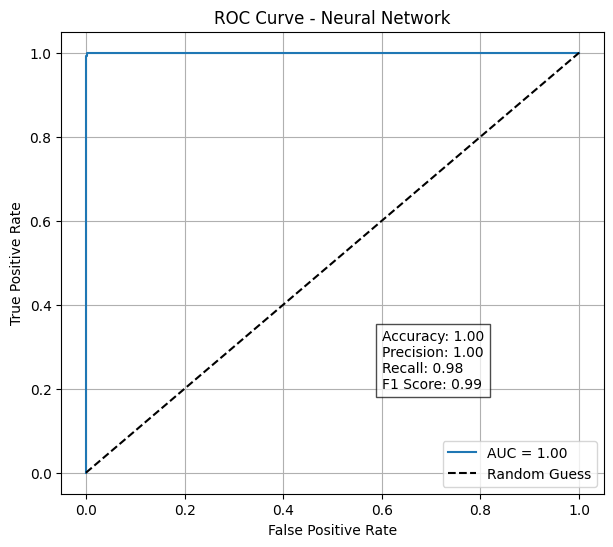

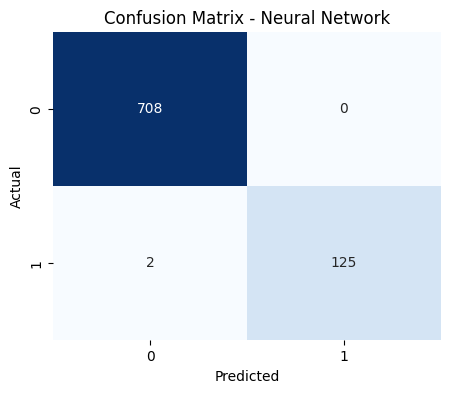

Accuracy for Neural Network: 0.9976



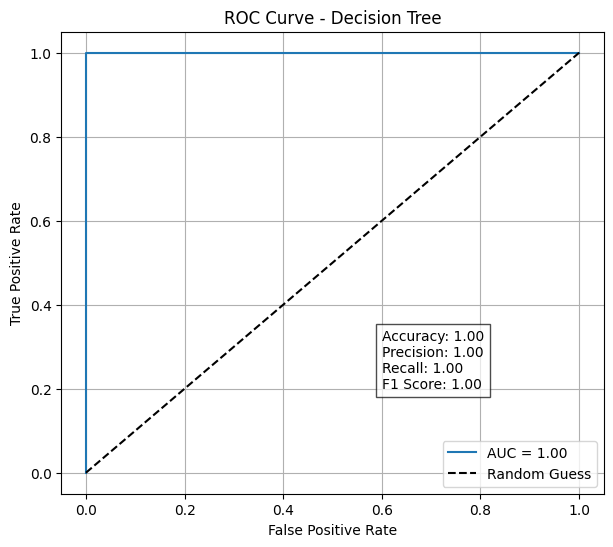

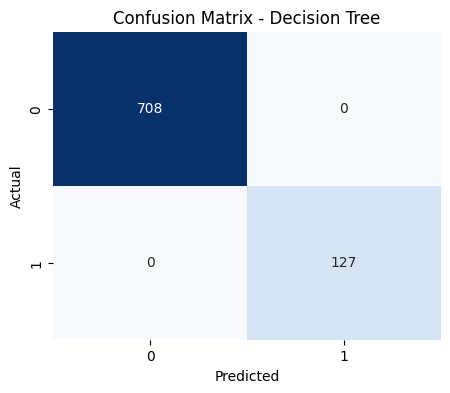

Accuracy for Decision Tree: 1.0000



In [ ]:
from sklearn.metrics import (
    roc_curve, auc, accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

for name, model in models.items():

    model.fit(X_train_scaled, y_train)

    # Predict probabilities for ROC
    if hasattr(model, "predict_proba"):
        y_probs = model.predict_proba(X_test_scaled)[:, 1]
    else:
        y_probs = model.decision_function(X_test_scaled)
        y_probs = (y_probs - y_probs.min()) / (y_probs.max() - y_probs.min())  # normalize

    # Predict class labels
    y_pred = model.predict(X_test_scaled)

    # ROC and AUC
    fpr, tpr, _ = roc_curve(y_test, y_probs)
    roc_auc = auc(fpr, tpr)

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)


    # Plot ROC Curve

    plt.figure(figsize=(7, 6))
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
    plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")

    # Add metrics box
    plt.text(0.6, 0.2,
             f"Accuracy: {acc:.2f}\n"
             f"Precision: {prec:.2f}\n"
             f"Recall: {rec:.2f}\n"
             f"F1 Score: {f1:.2f}",
             bbox=dict(facecolor="white", alpha=0.7))

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve - {name}")
    plt.legend(loc="lower right")
    plt.grid()
    plt.show()


    # Plot Confusion Matrix

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix - {name}")
    plt.show()


    print(f"Accuracy for {name}: {acc:.4f}\n")


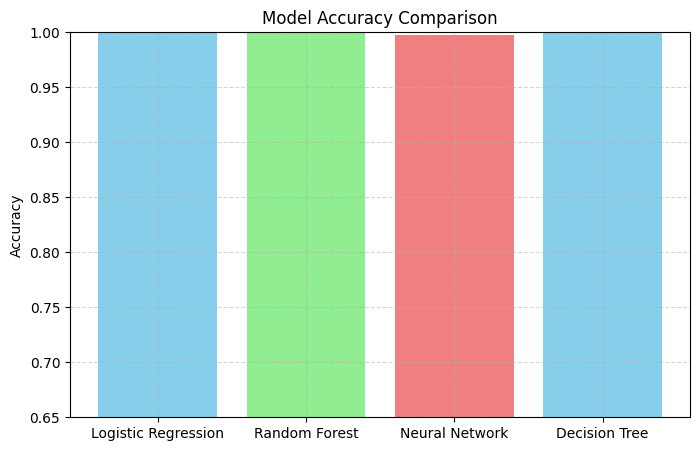

In [ ]:
plt.figure(figsize=(8, 5))
plt.bar(results.keys(), [v['accuracy'] for v in results.values()], color=['skyblue', 'lightgreen', 'lightcoral'])
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.ylim(0.65, 1.0)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

TREATING DATASET AS UNSUPERVISED

APPLYING KMEANS CLUSTER

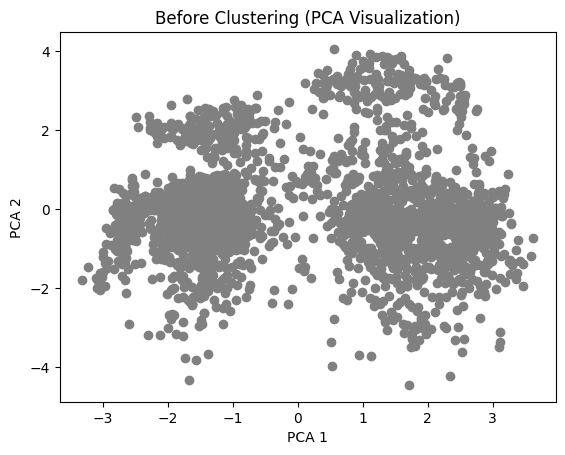

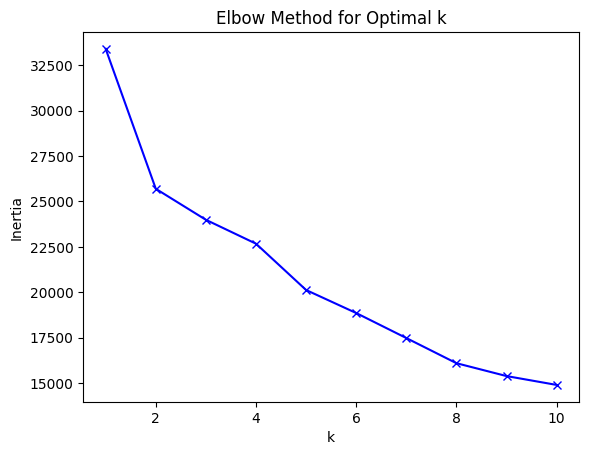

Cluster Centers:
[[-3.60741715e-01 -3.59584112e-01 -1.07794414e-01 -2.14916114e-02
  -1.77918766e-02  8.52645836e-02 -1.08468374e-30 -8.94997135e-01
  -8.54403889e-01 -7.34326264e-01 -3.31085814e-01  6.34575877e-01]
 [-3.61303993e-02 -6.87248405e-02  1.05286781e-01  4.25224714e-02
   5.06024078e-02 -2.81335045e-01 -4.53922781e-02  1.02034882e+00
   9.55509221e-01  7.79338471e-01  4.47731089e-01 -6.57957541e-01]
 [ 1.36749438e+00  1.47966039e+00 -5.00368814e-03 -7.77166345e-02
  -1.19211762e-01  7.09667465e-01  1.61742600e-01 -5.62387806e-01
  -4.70743641e-01 -2.55344304e-01 -4.58445411e-01  1.65371203e-01]]


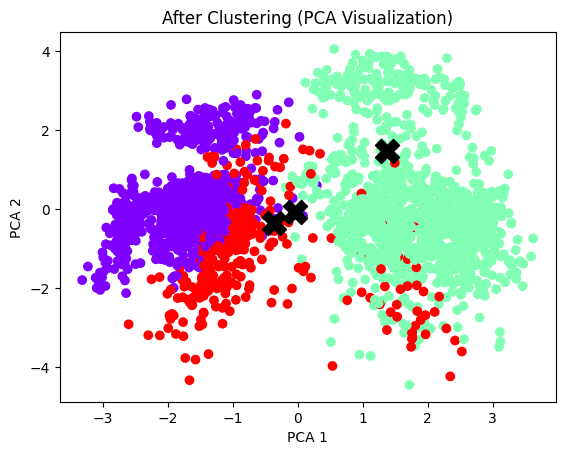

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Select only numeric columns
X = df.select_dtypes(include=['float64','int64'])

# Handle missing values (fill with mean)
X = X.fillna(X.mean())

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Show raw data before clustering (PCA for visualization)
pca = PCA(n_components=2)
X_pca_before = pca.fit_transform(X_scaled)
plt.scatter(X_pca_before[:,0], X_pca_before[:,1], c='gray')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('Before Clustering (PCA Visualization)')
plt.show()

# Elbow Method to find optimal k
inertia = []
K = range(1, 11)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=0)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(K, inertia, 'bx-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.show()

# Apply KMeans clustering with chosen k (example: 3)
kmeans = KMeans(n_clusters=3, random_state=0)
kmeans.fit(X_scaled)
y_kmeans = kmeans.predict(X_scaled)

# Add cluster labels to dataframe
df['Cluster'] = y_kmeans

print("Cluster Centers:")
print(kmeans.cluster_centers_)

# Show data after clustering (PCA visualization)
X_pca_after = pca.fit_transform(X_scaled)
plt.scatter(X_pca_after[:,0], X_pca_after[:,1], c=y_kmeans, cmap='rainbow')
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], s=300, c='black', marker='X')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('After Clustering (PCA Visualization)')
plt.show()


Cluster Centers:
[[-3.60741715e-01 -3.59584112e-01 -1.07794414e-01 -2.14916114e-02
  -1.77918766e-02  8.52645836e-02 -1.08468374e-30 -8.94997135e-01
  -8.54403889e-01 -7.34326264e-01 -3.31085814e-01  6.34575877e-01]
 [-3.61303993e-02 -6.87248405e-02  1.05286781e-01  4.25224714e-02
   5.06024078e-02 -2.81335045e-01 -4.53922781e-02  1.02034882e+00
   9.55509221e-01  7.79338471e-01  4.47731089e-01 -6.57957541e-01]
 [ 1.36749438e+00  1.47966039e+00 -5.00368814e-03 -7.77166345e-02
  -1.19211762e-01  7.09667465e-01  1.61742600e-01 -5.62387806e-01
  -4.70743641e-01 -2.55344304e-01 -4.58445411e-01  1.65371203e-01]]


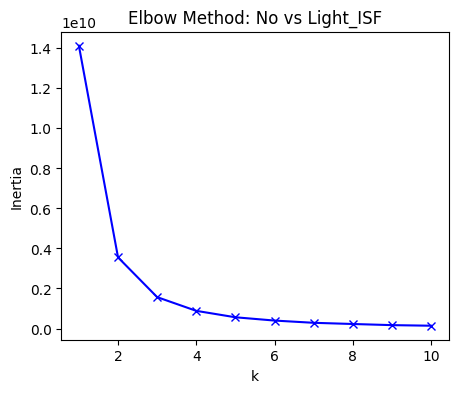

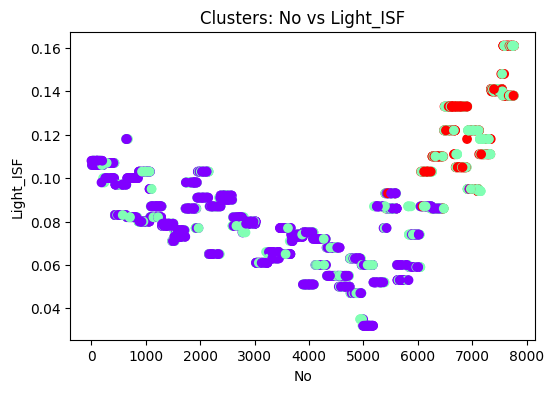

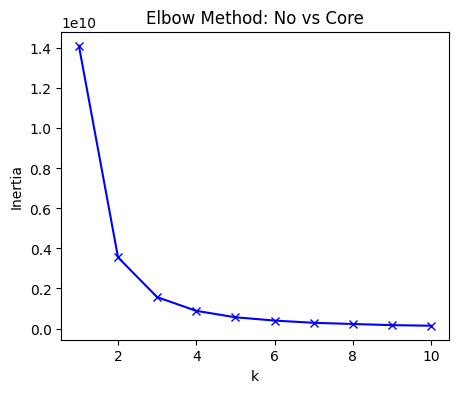

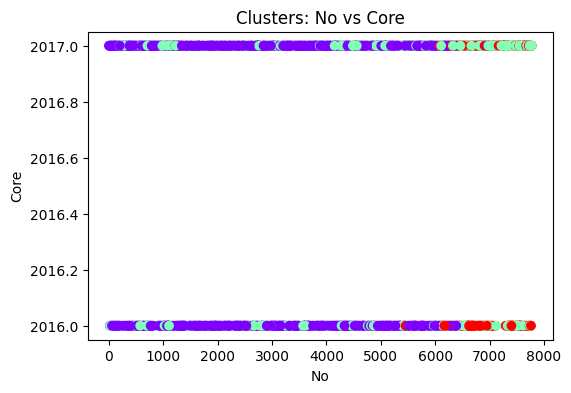

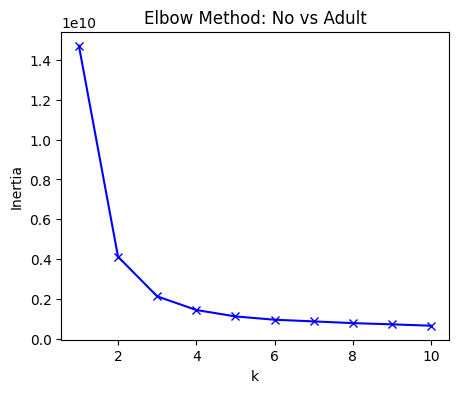

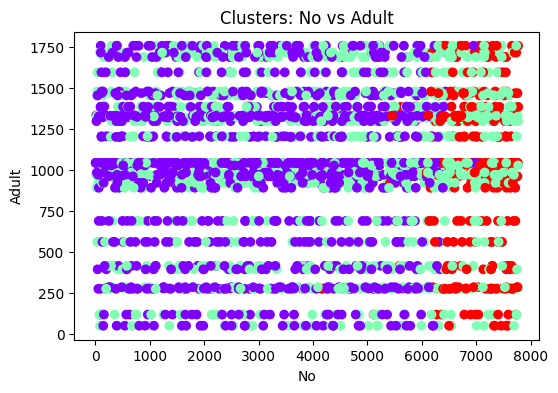

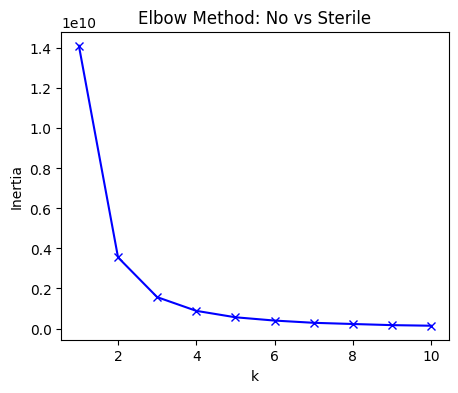

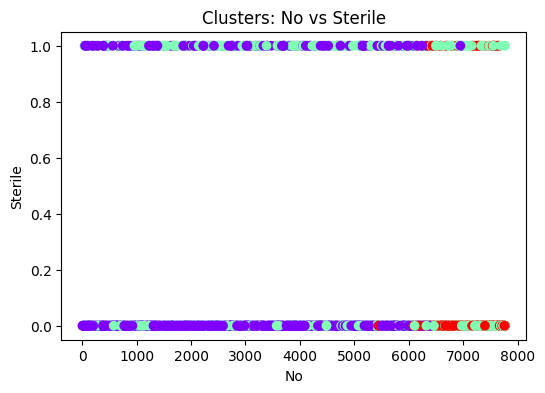

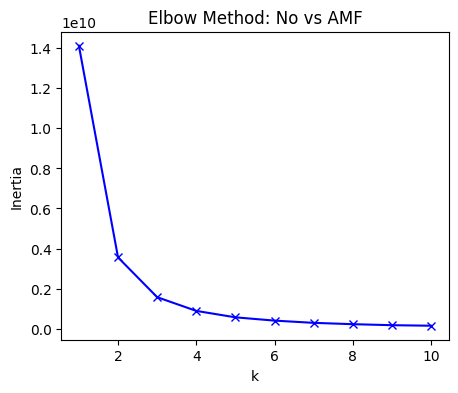

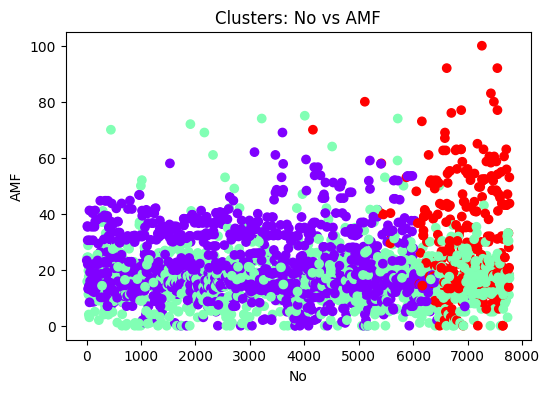

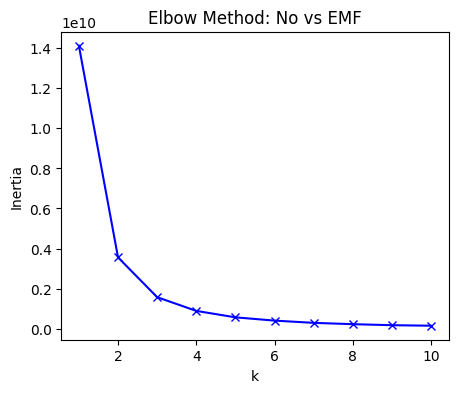

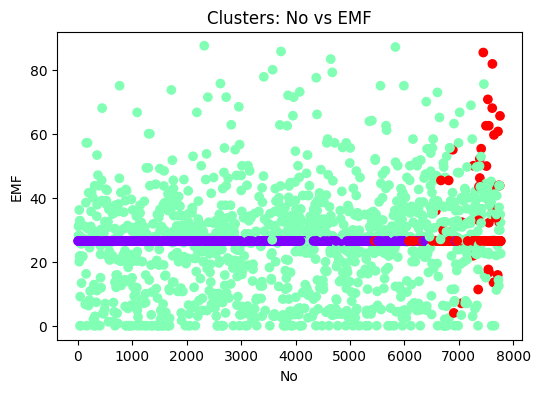

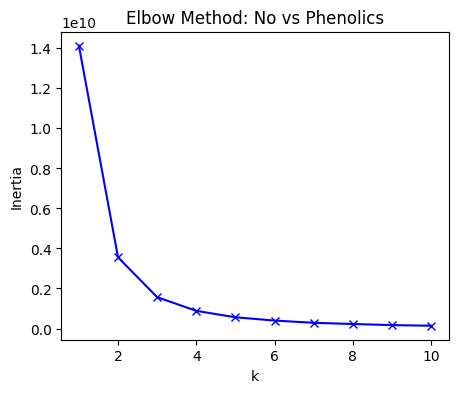

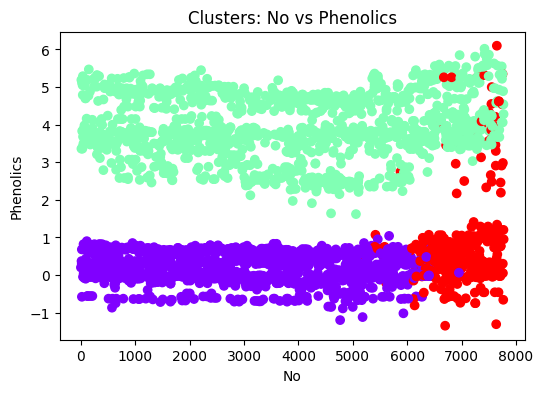

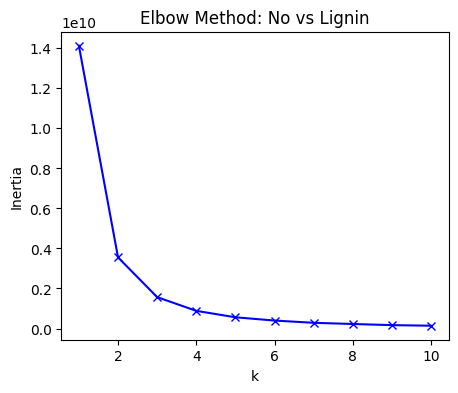

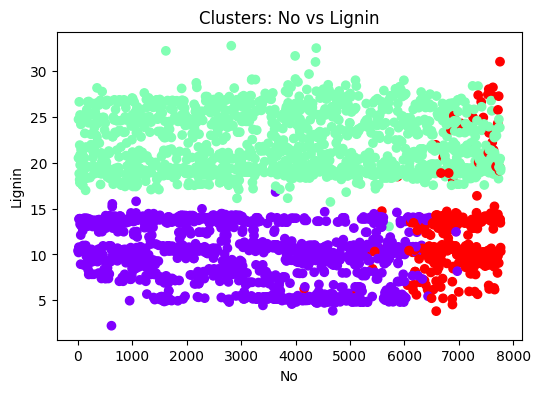

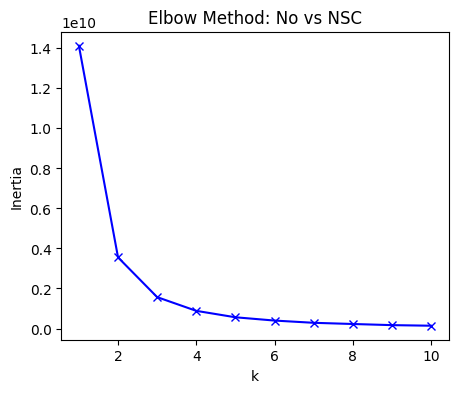

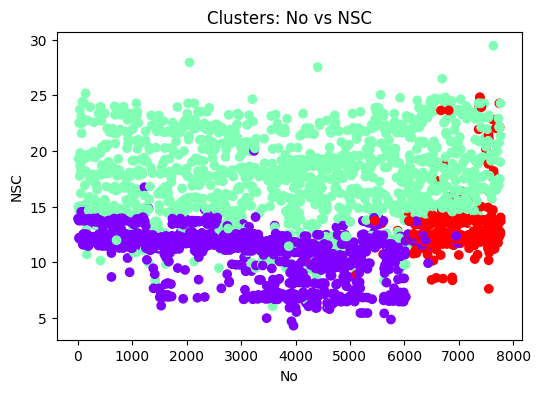

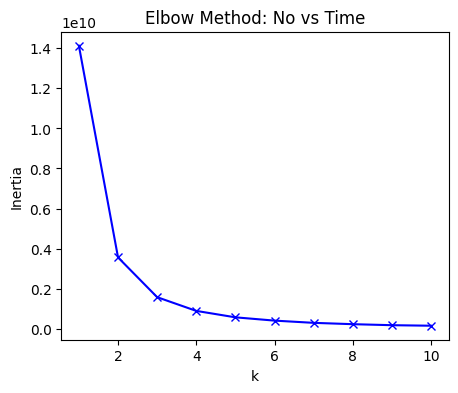

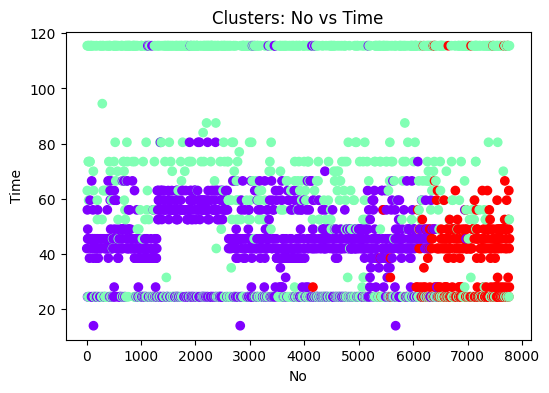

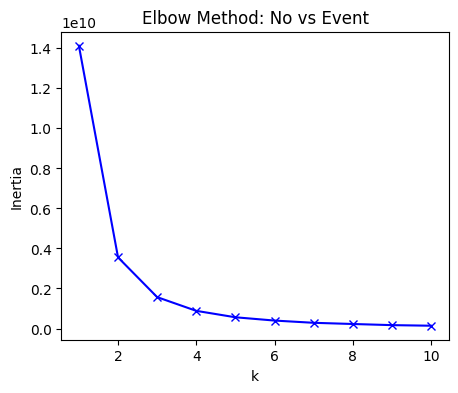

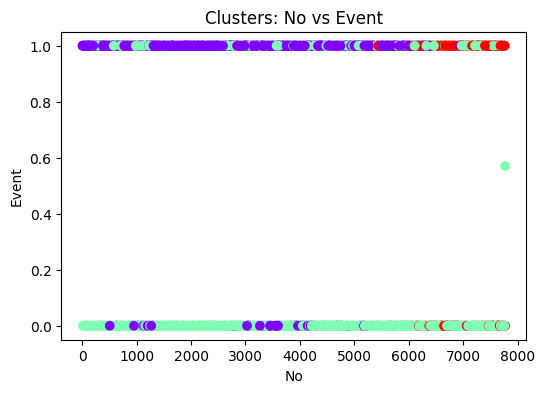

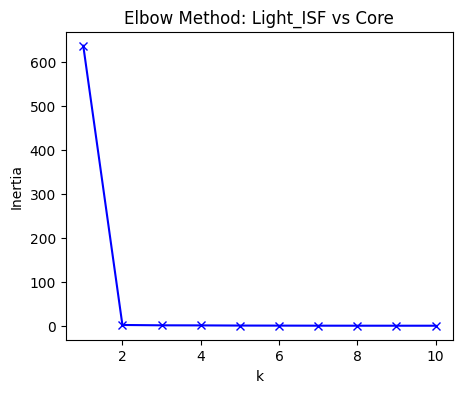

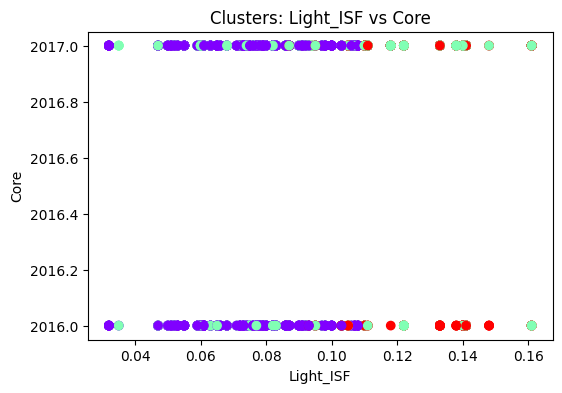

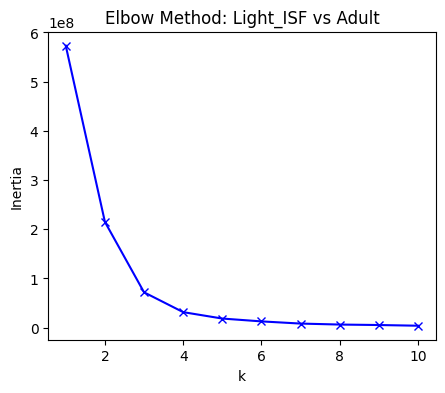

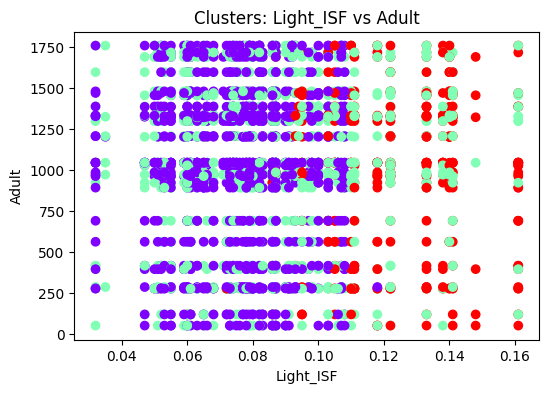

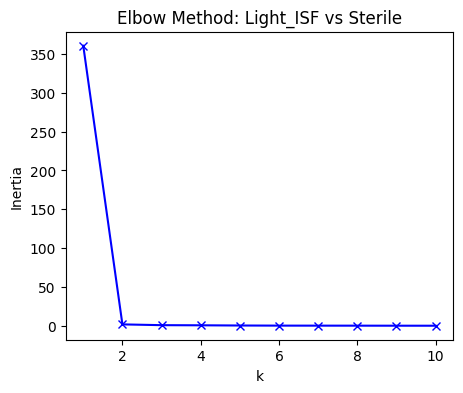

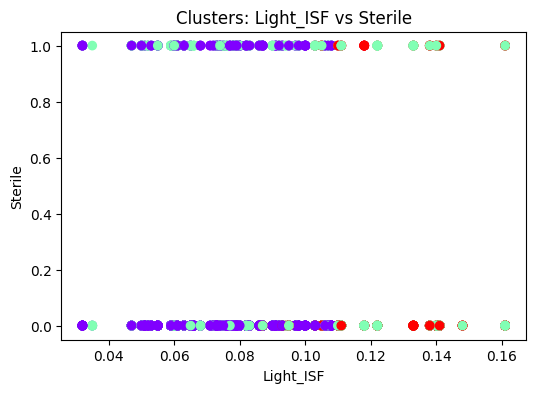

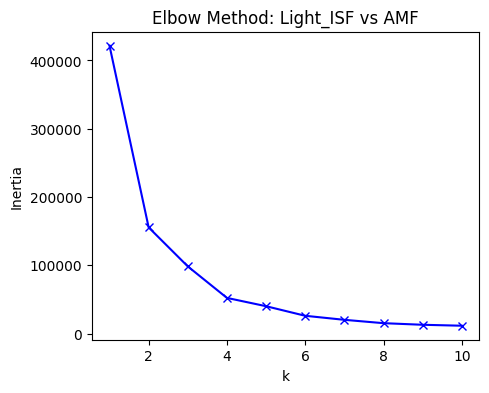

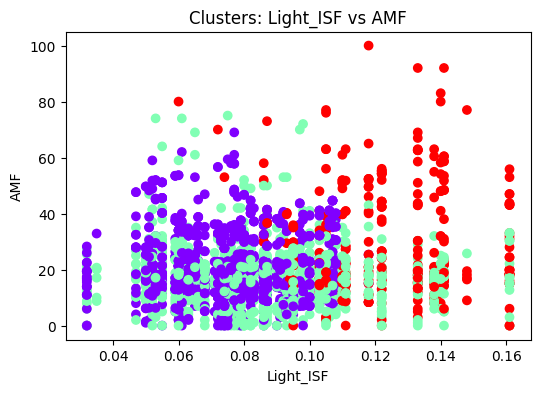

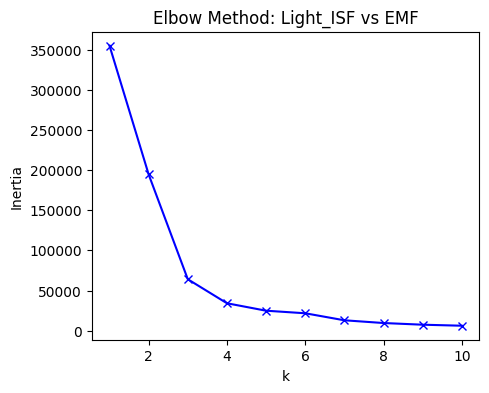

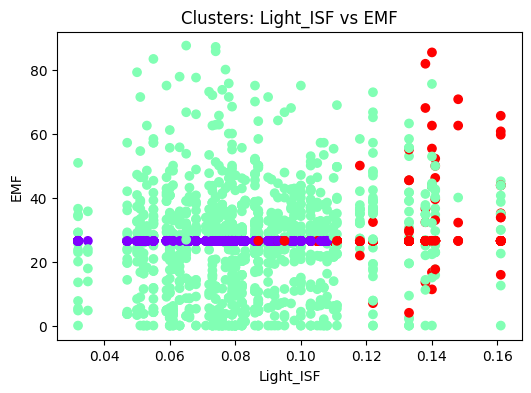

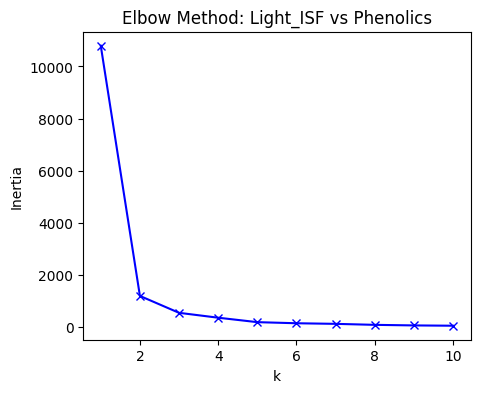

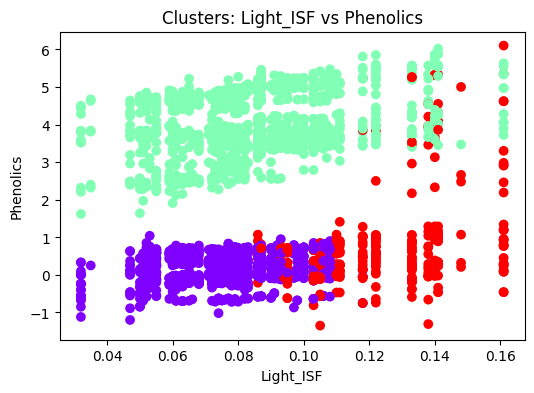

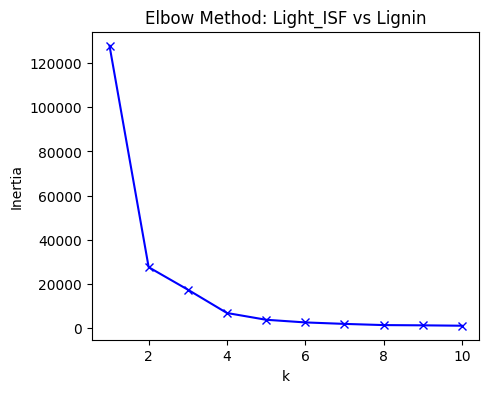

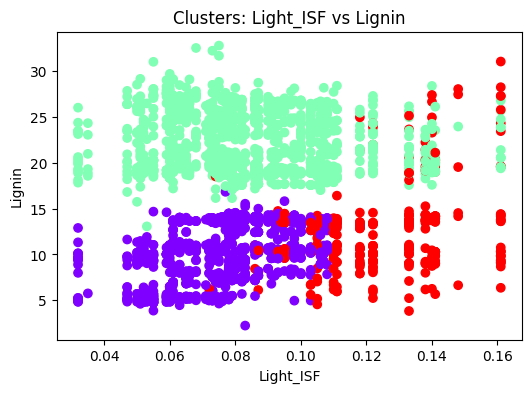

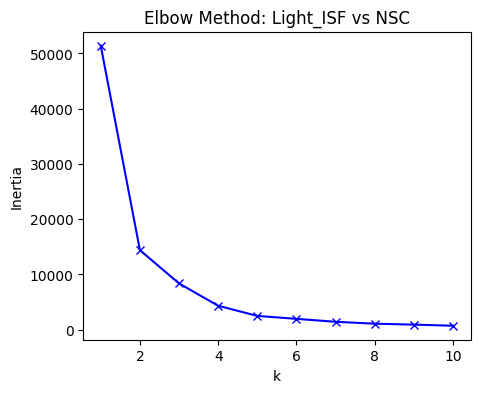

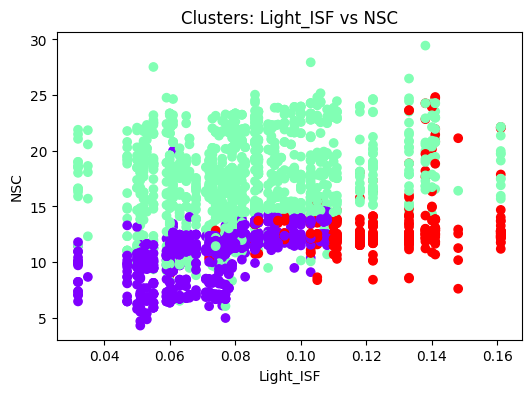

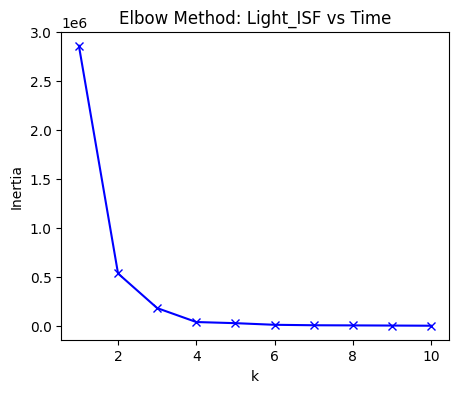

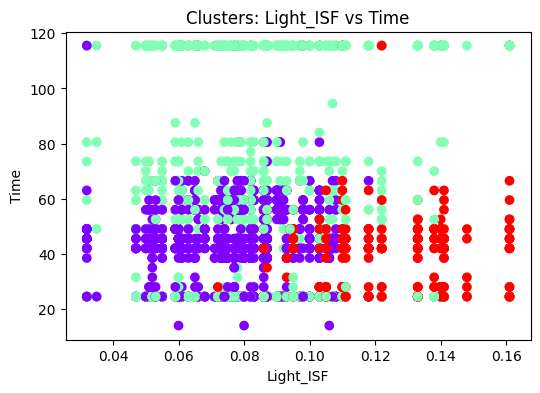

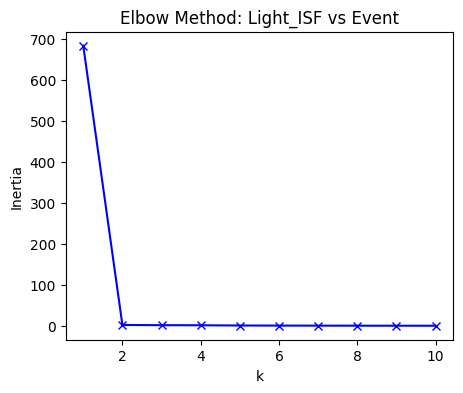

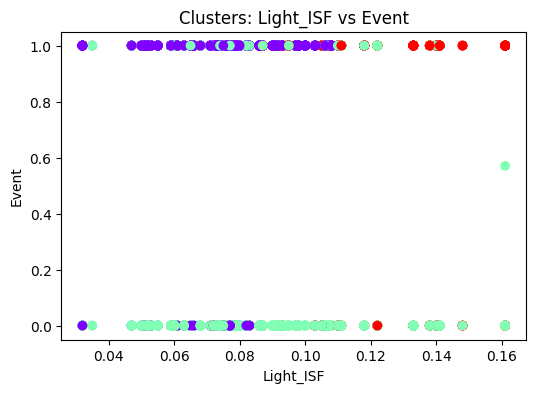

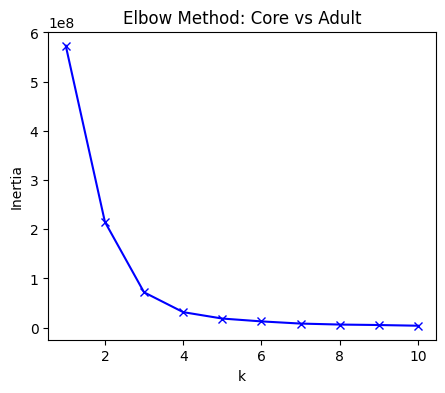

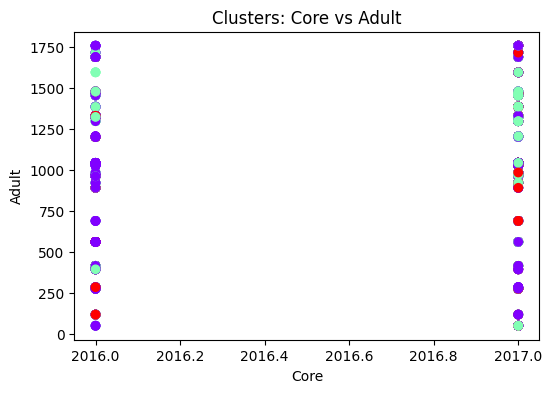

/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (5). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (6). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (7). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (8). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.12/dist-packages/sklearn/base.py:

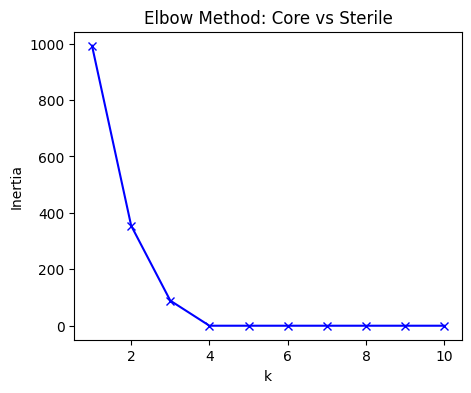

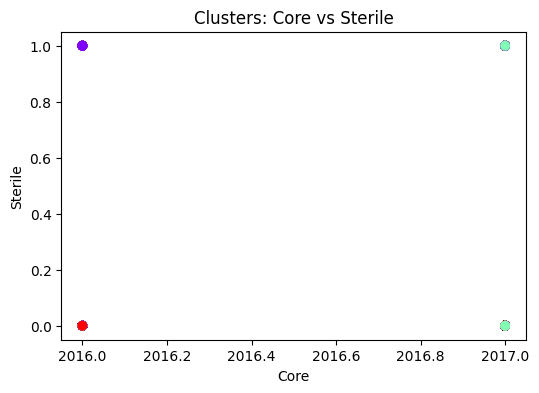

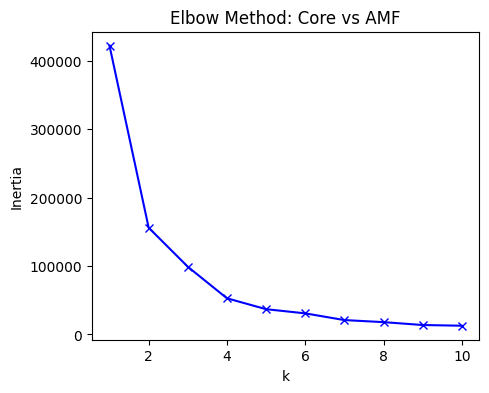

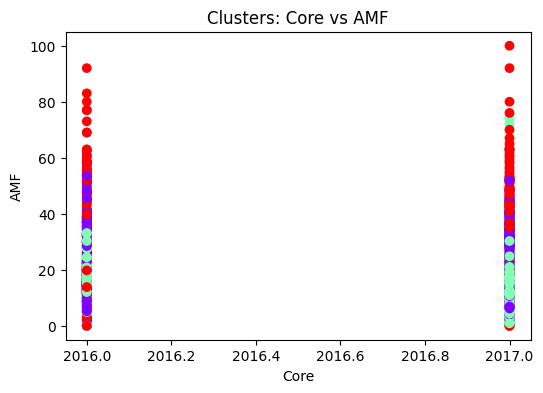

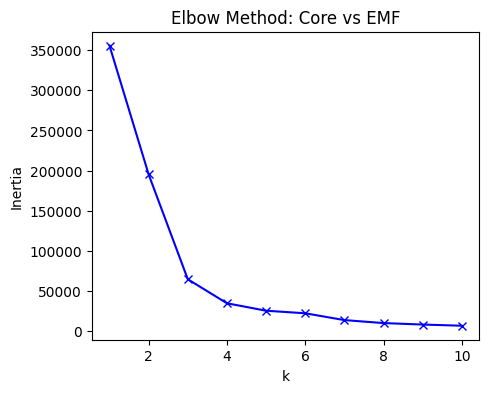

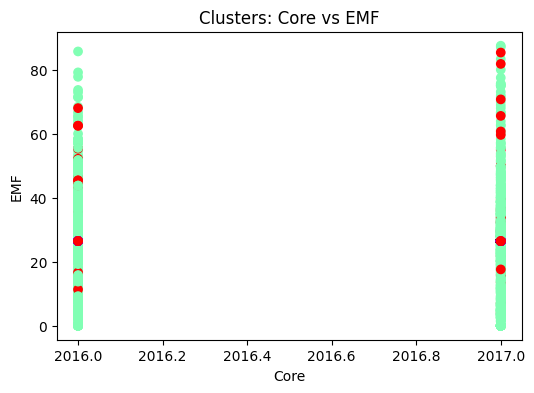

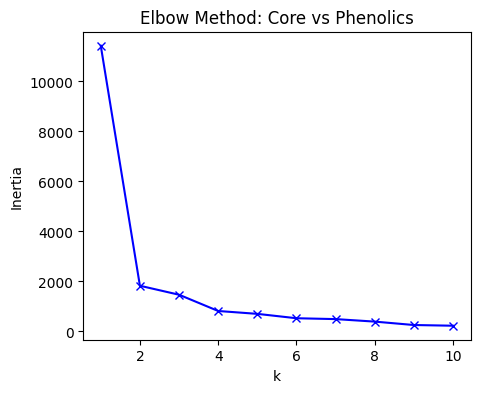

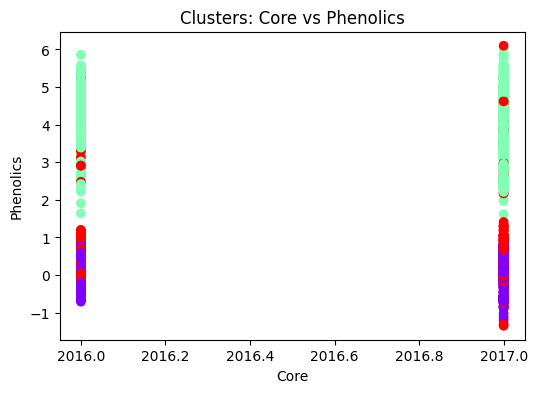

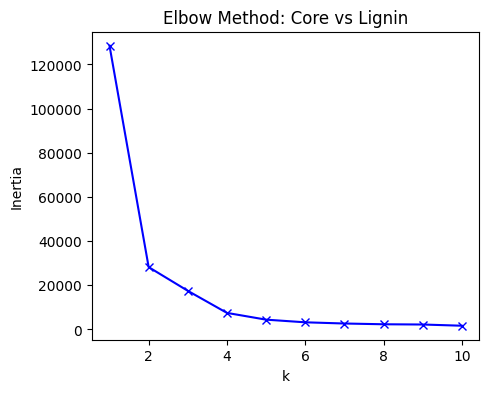

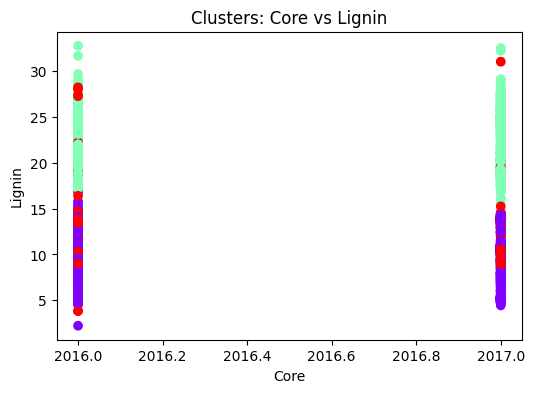

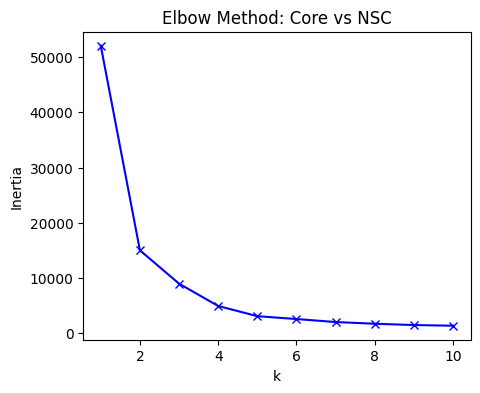

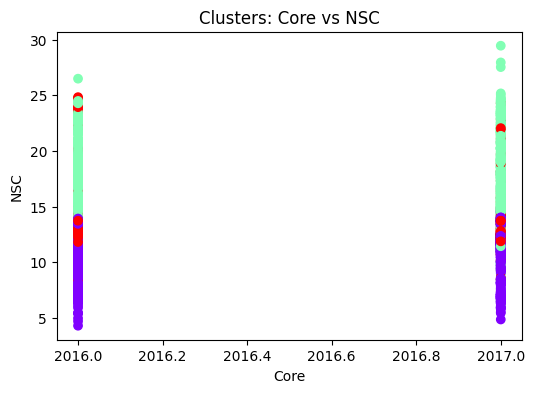

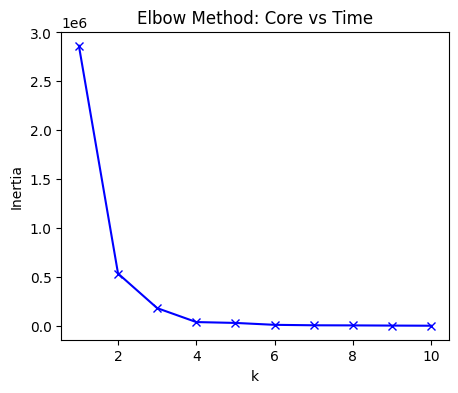

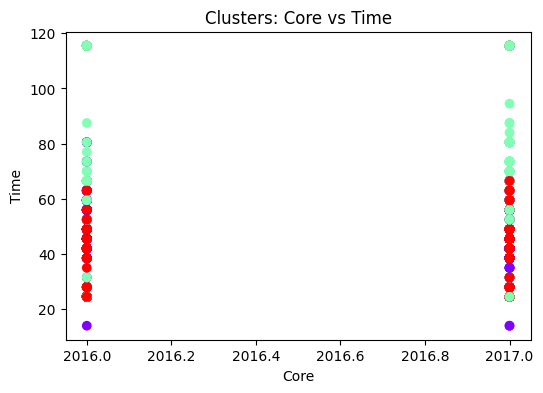

/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (5) found smaller than n_clusters (6). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (5) found smaller than n_clusters (7). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (5) found smaller than n_clusters (8). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (5) found smaller than n_clusters (9). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.12/dist-packages/sklearn/base.py:

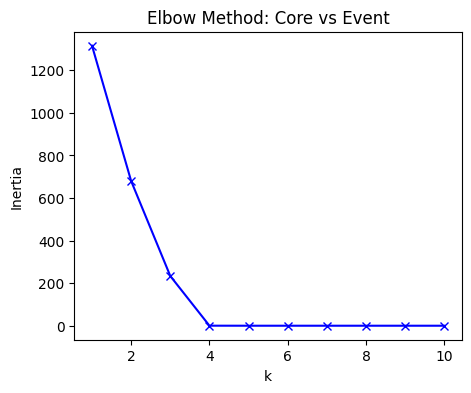

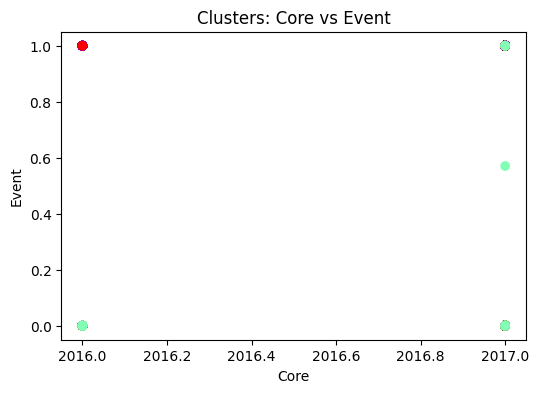

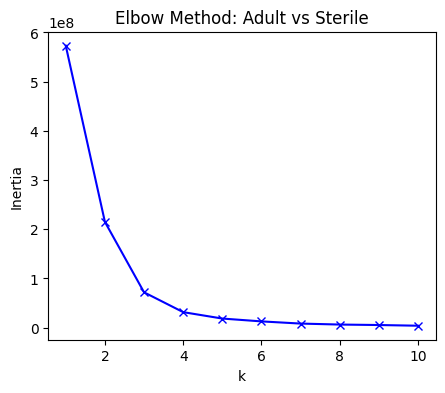

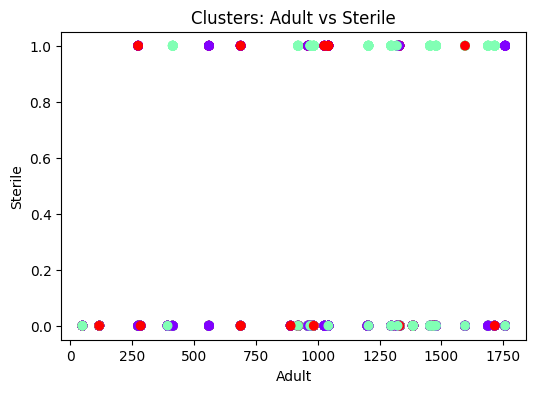

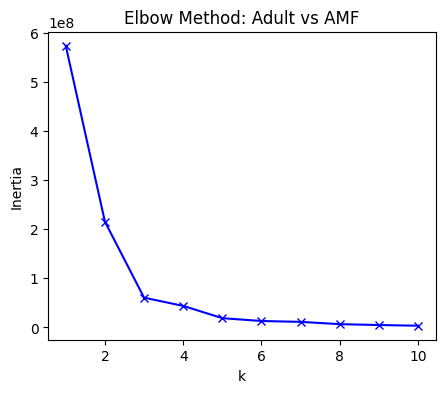

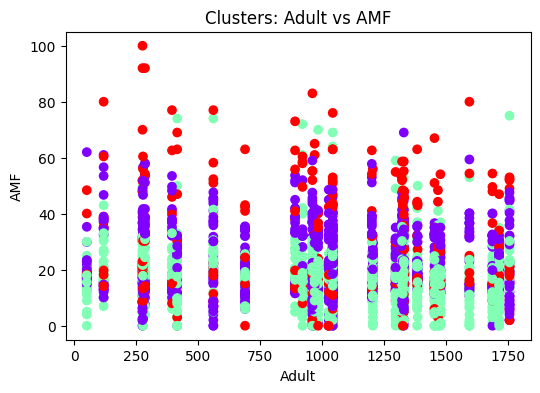

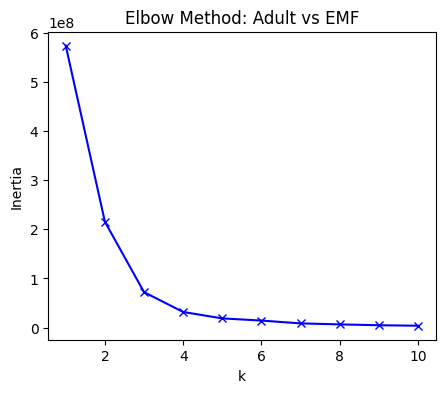

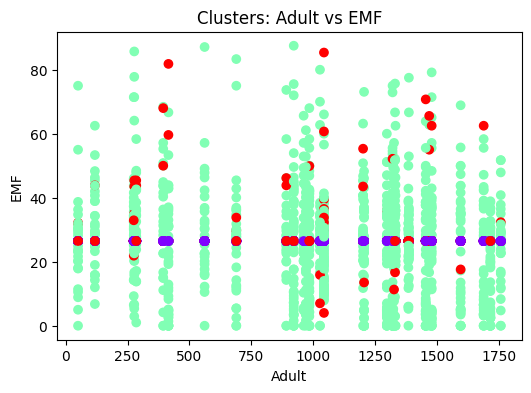

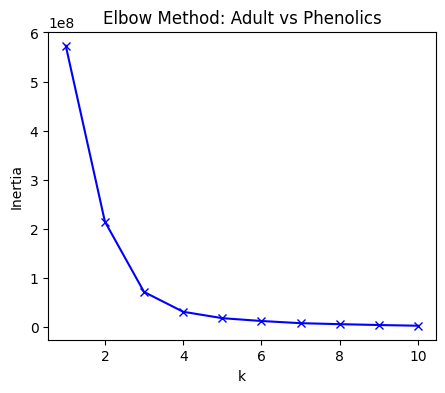

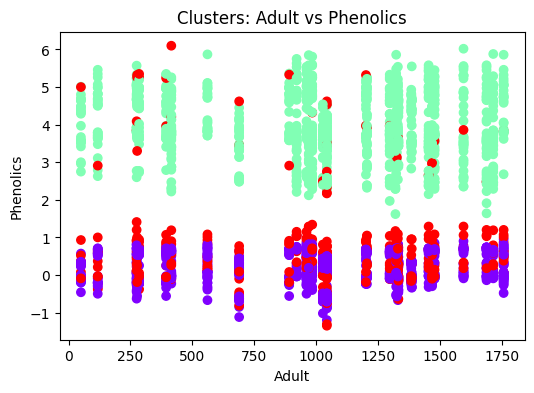

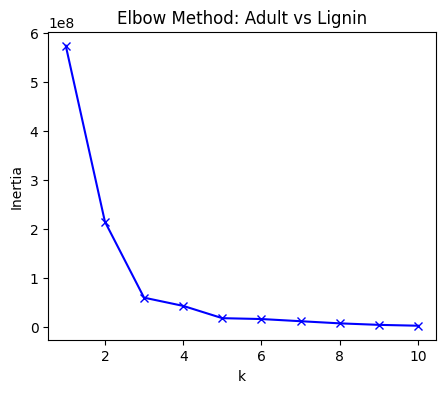

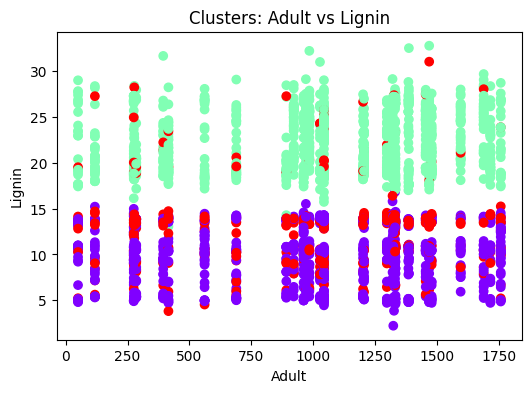

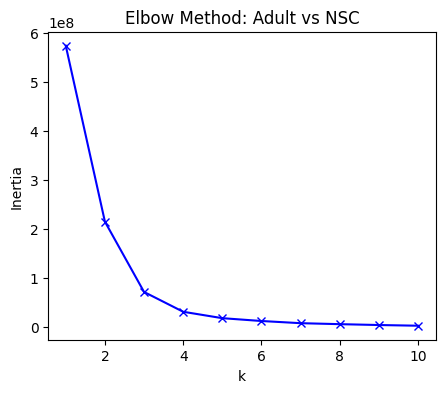

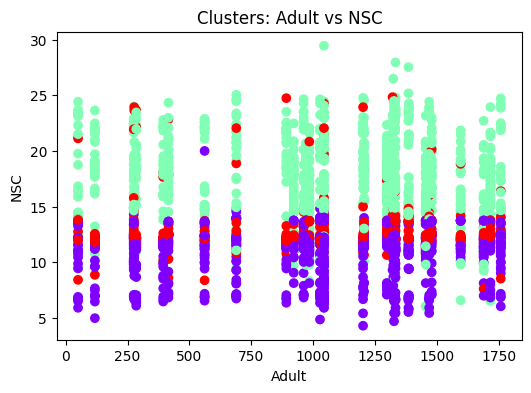

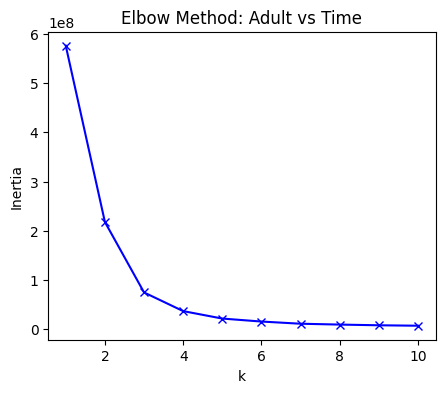

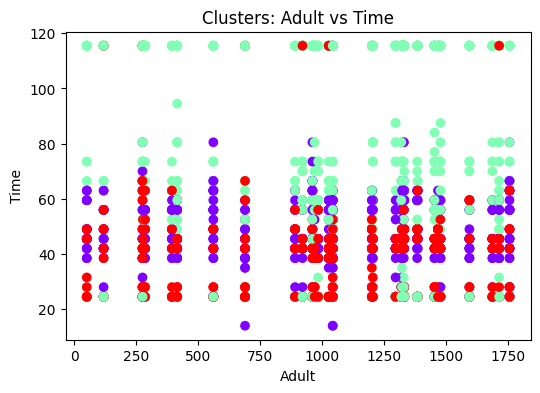

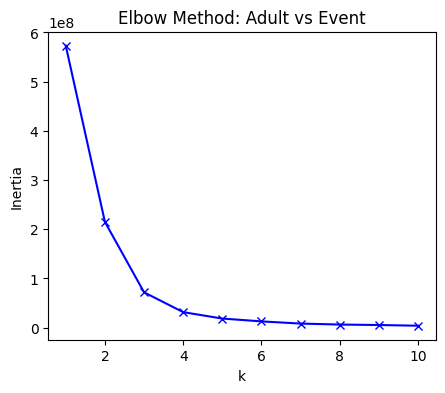

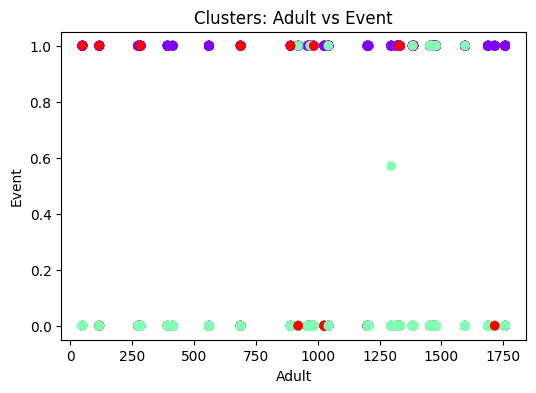

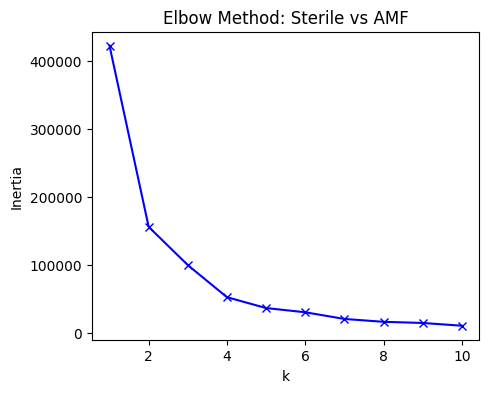

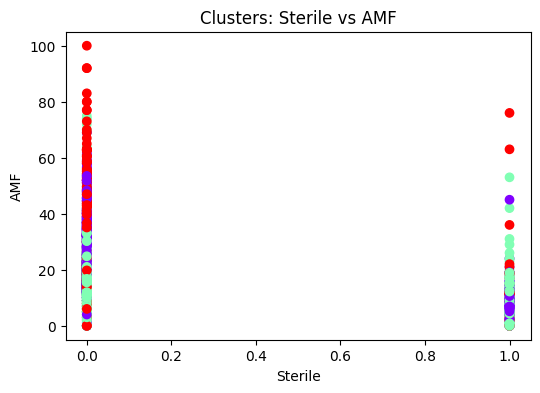

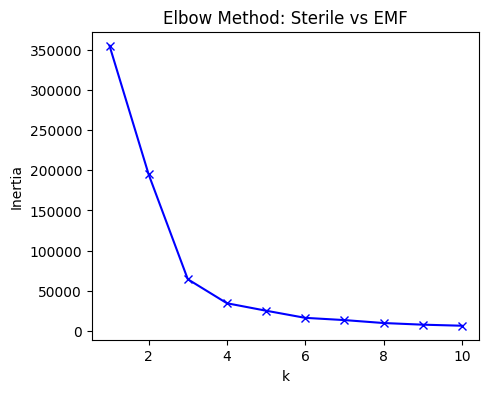

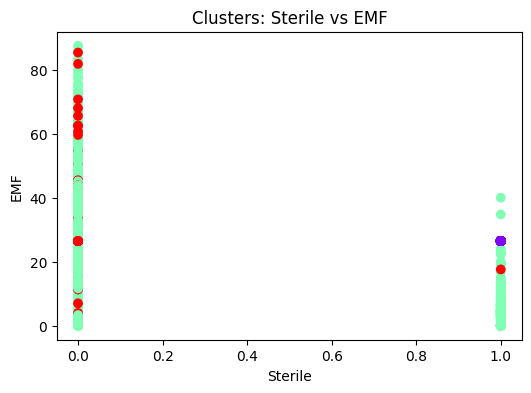

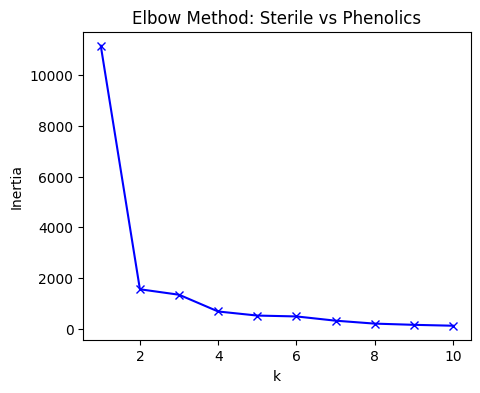

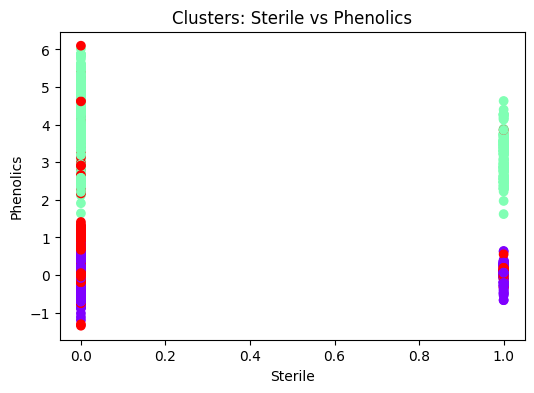

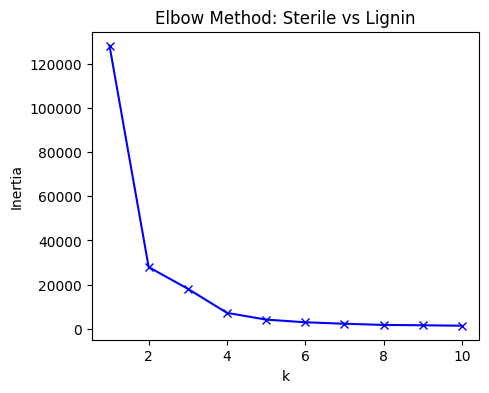

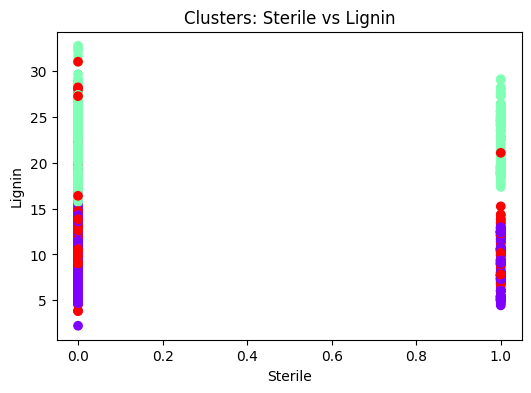

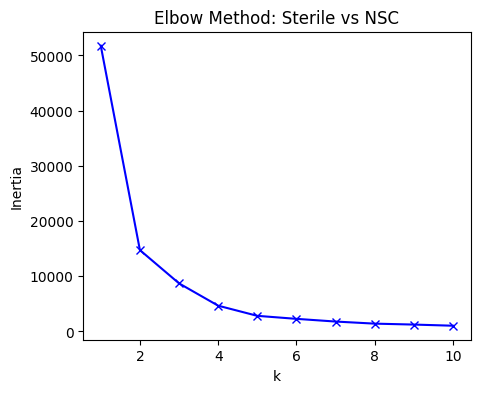

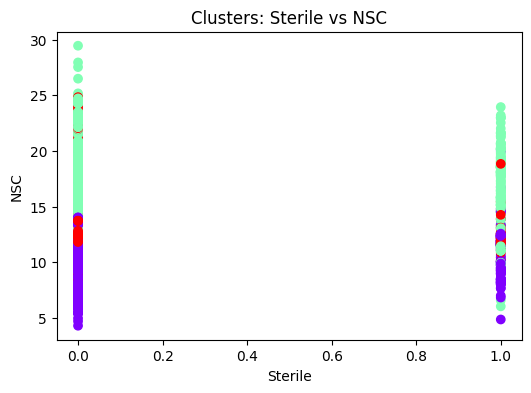

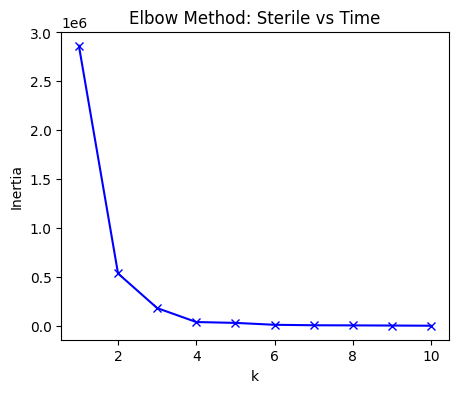

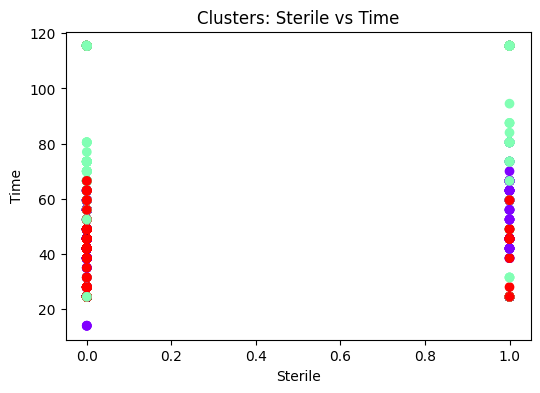

/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (5) found smaller than n_clusters (6). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (5) found smaller than n_clusters (7). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (5) found smaller than n_clusters (8). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (5) found smaller than n_clusters (9). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.12/dist-packages/sklearn/base.py:

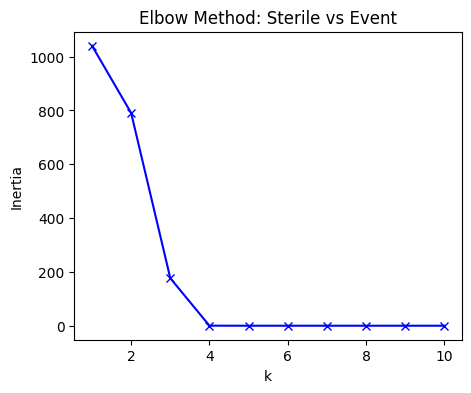

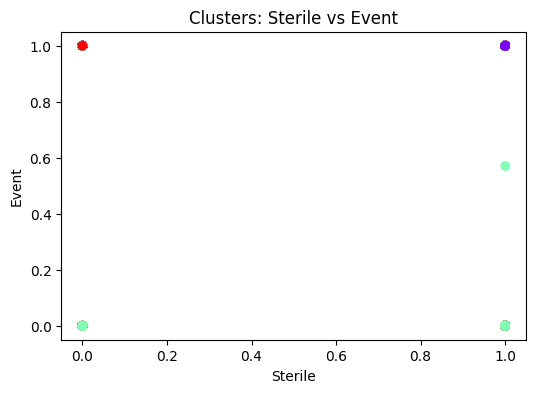

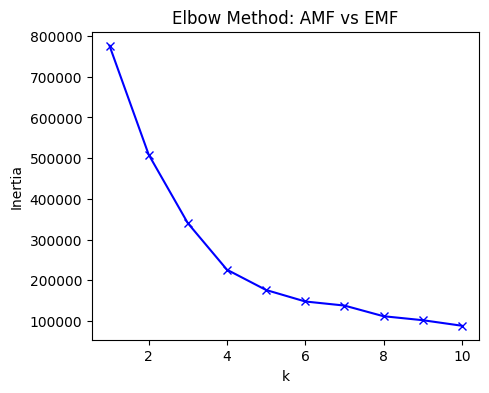

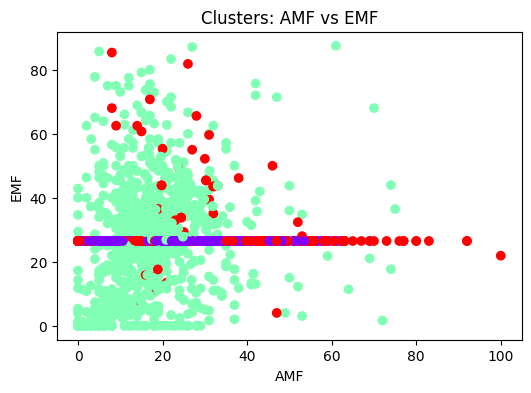

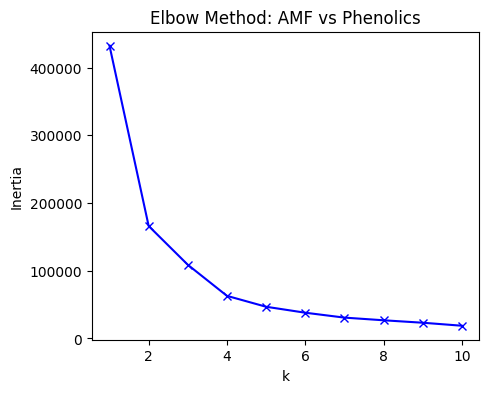

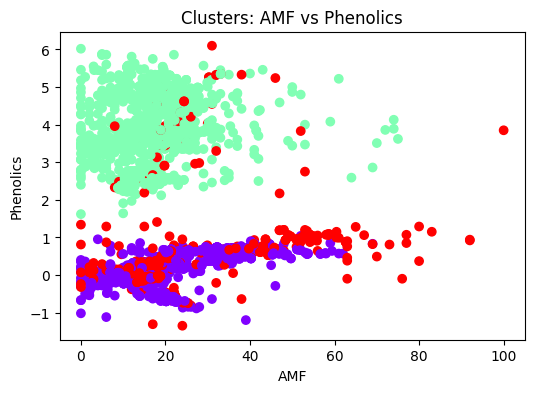

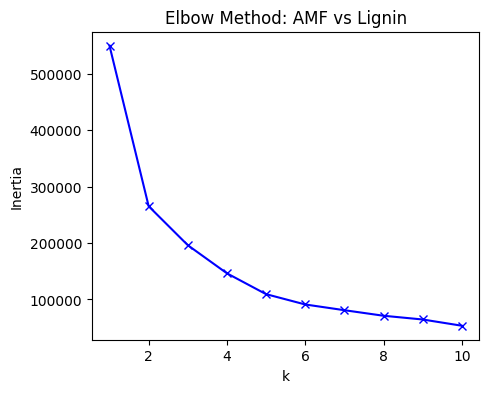

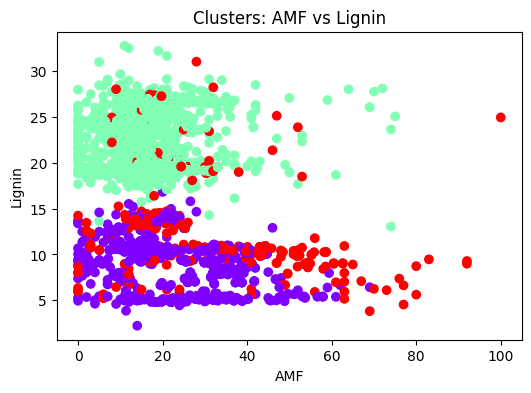

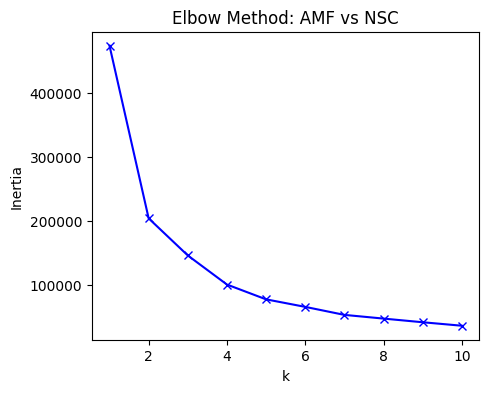

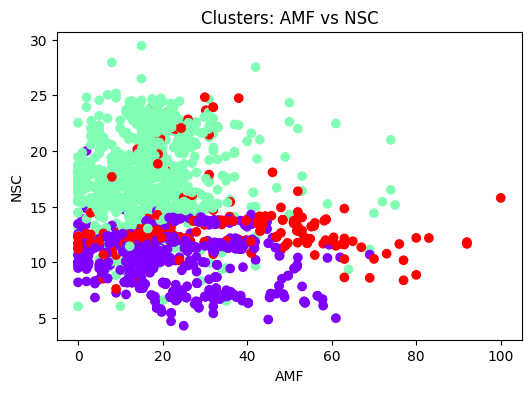

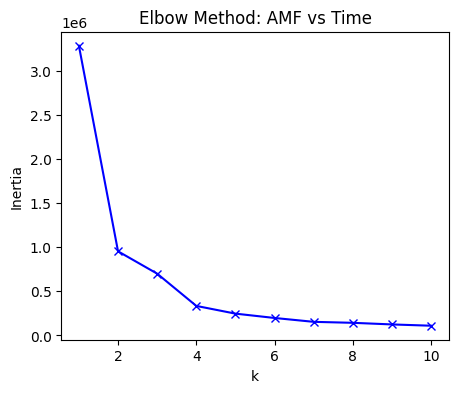

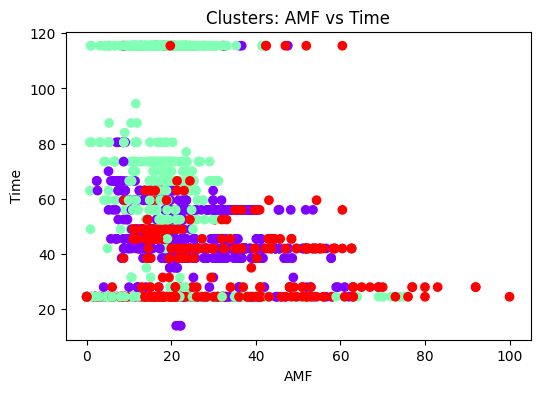

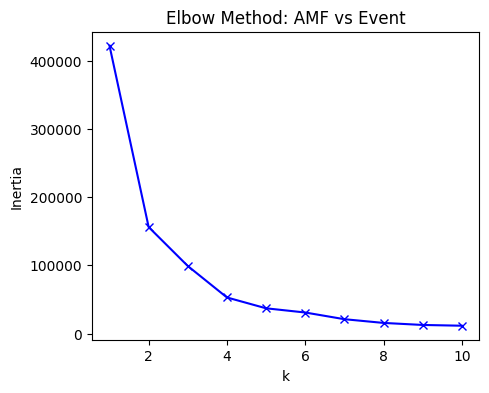

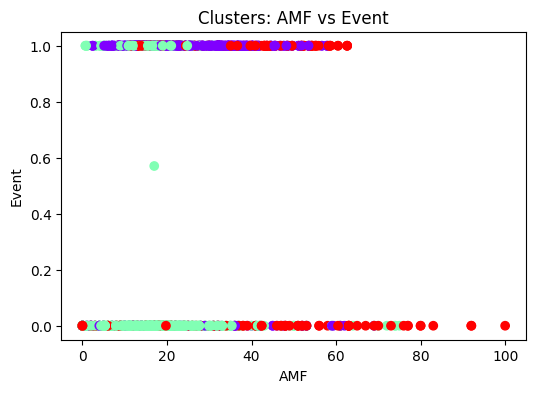

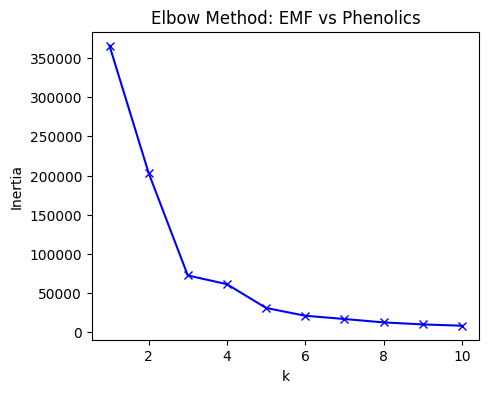

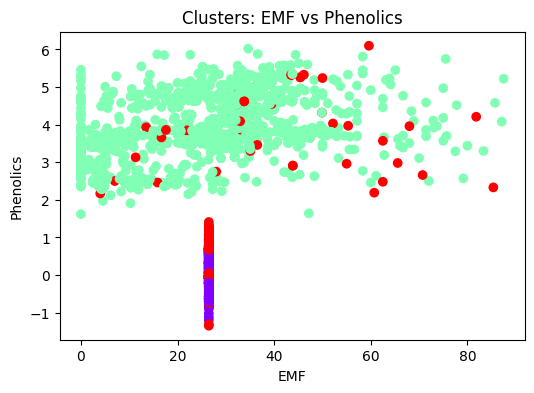

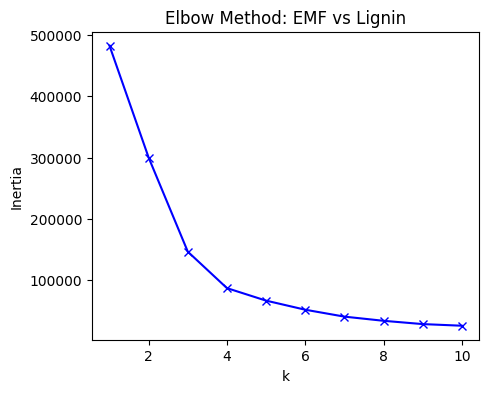

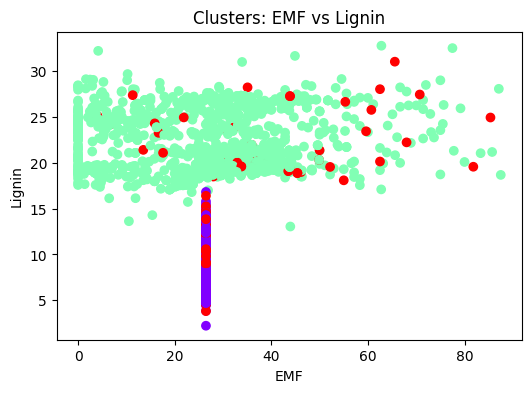

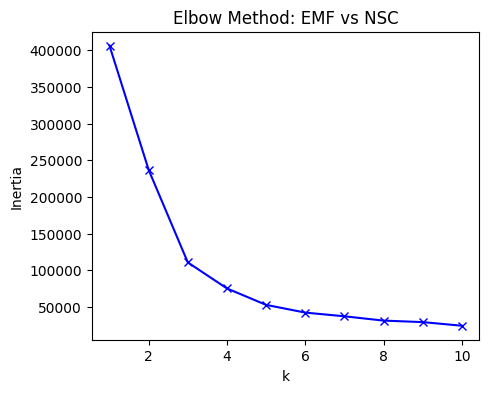

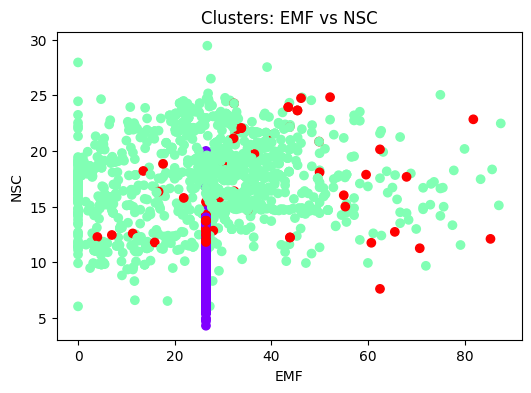

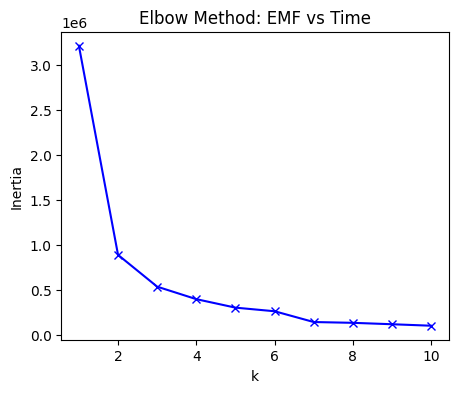

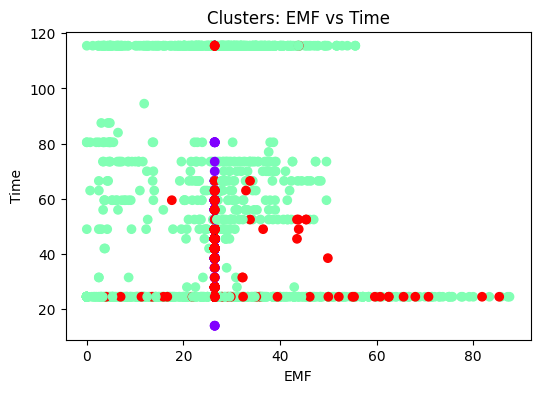

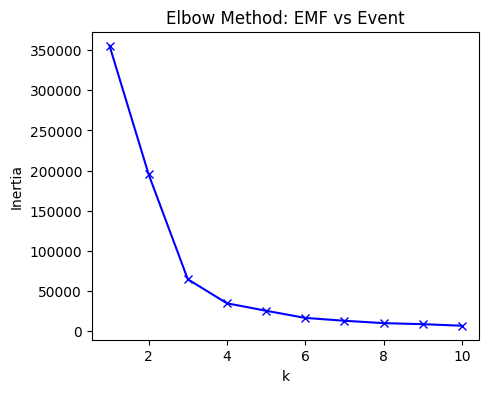

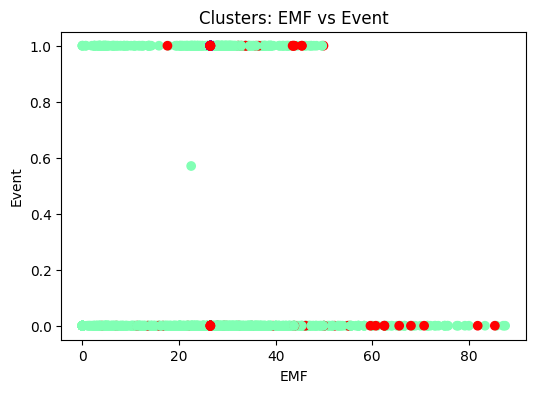

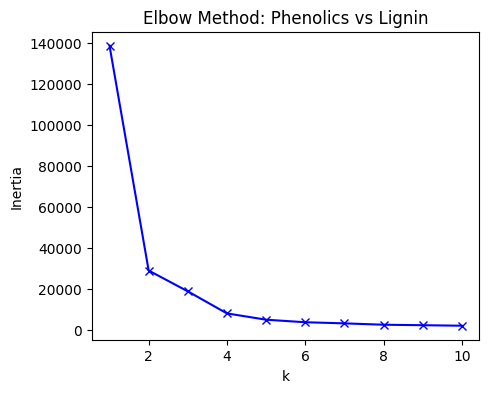

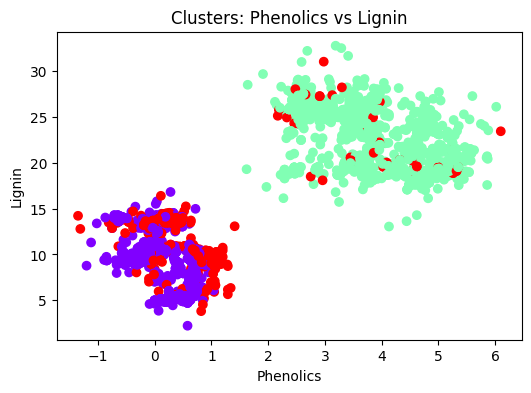

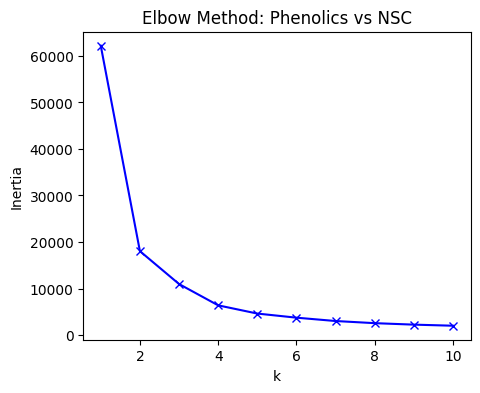

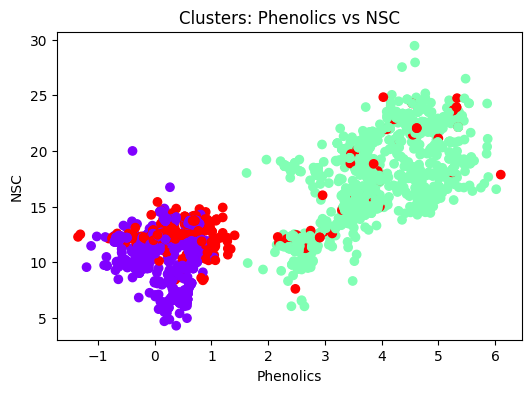

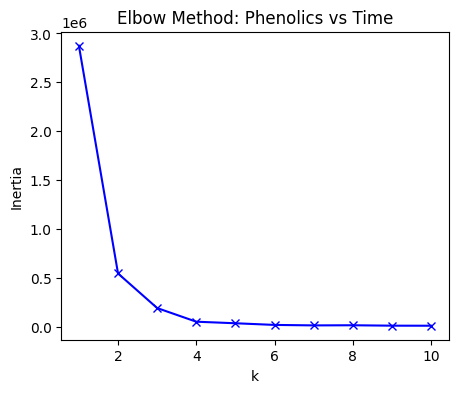

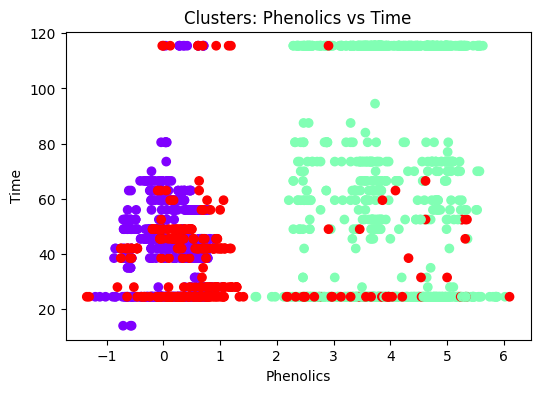

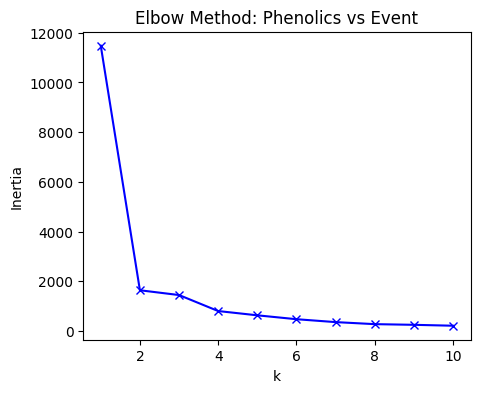

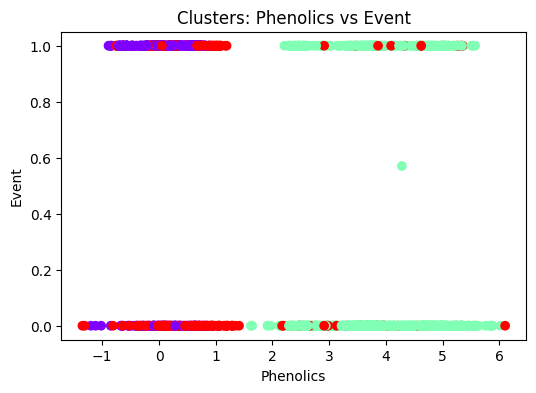

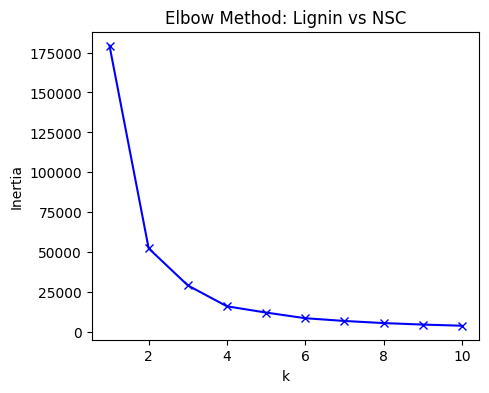

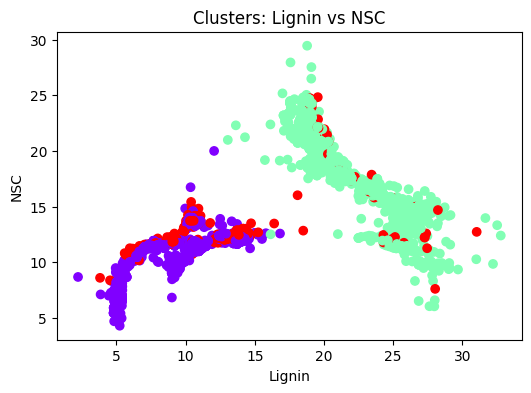

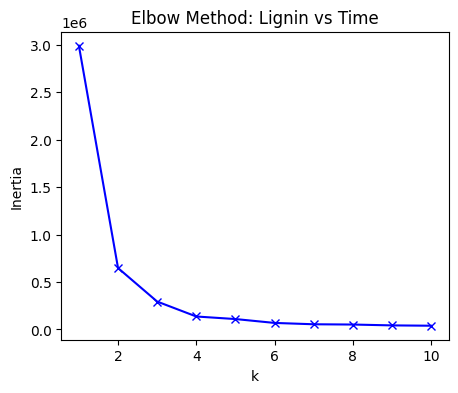

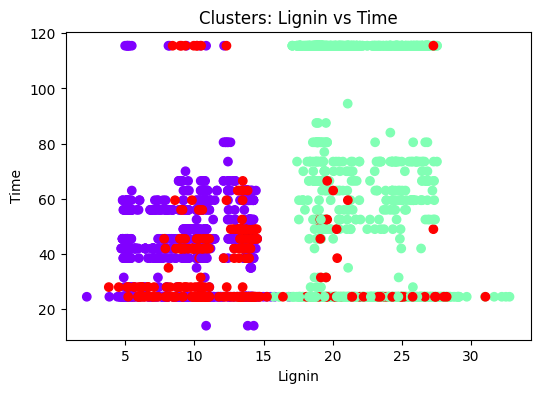

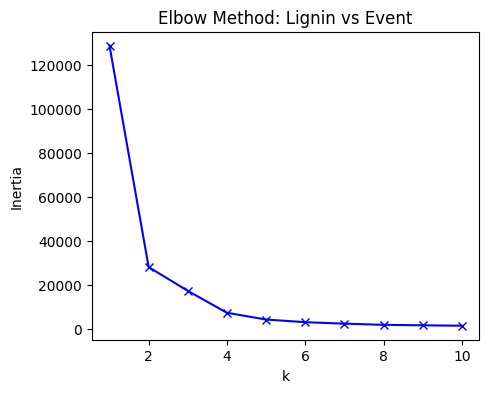

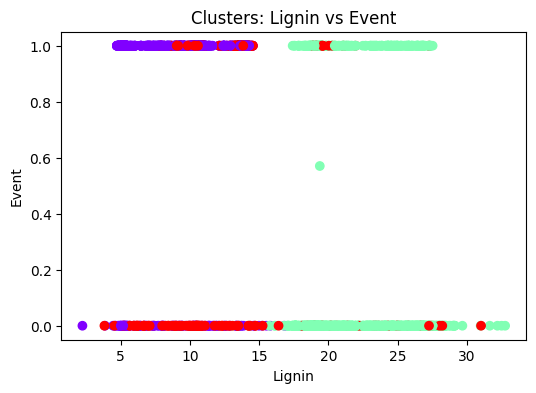

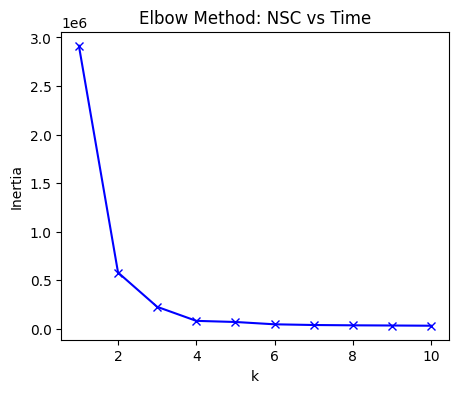

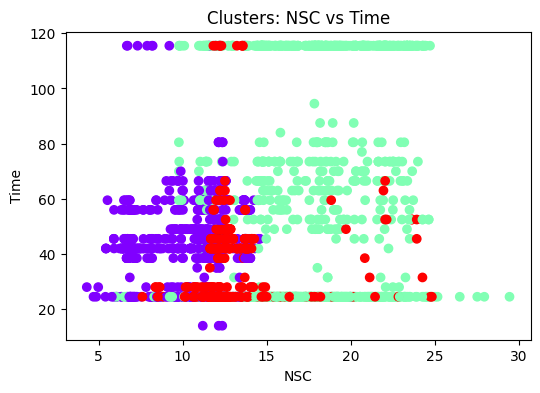

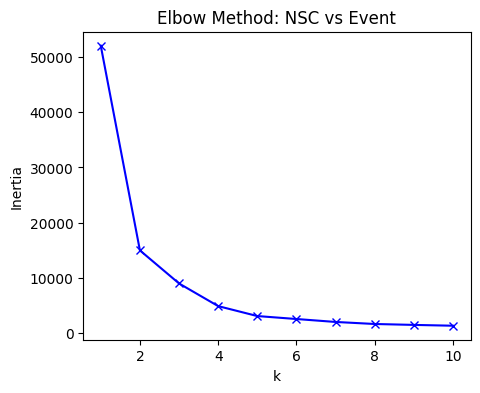

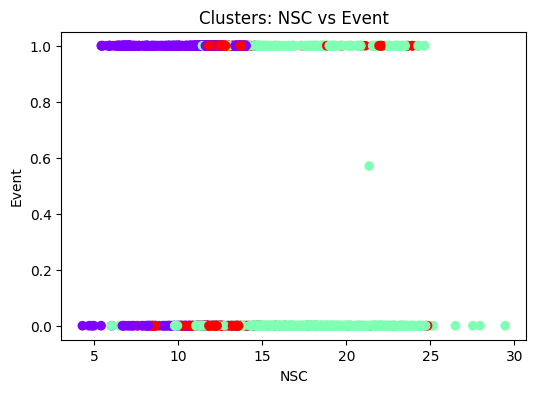

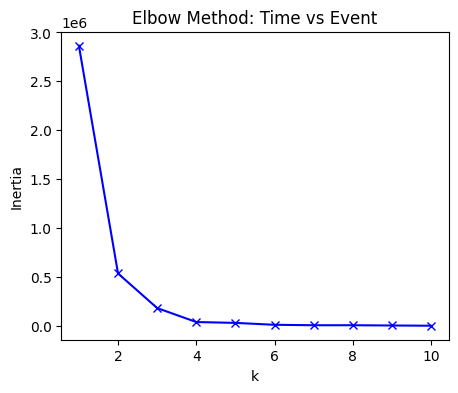

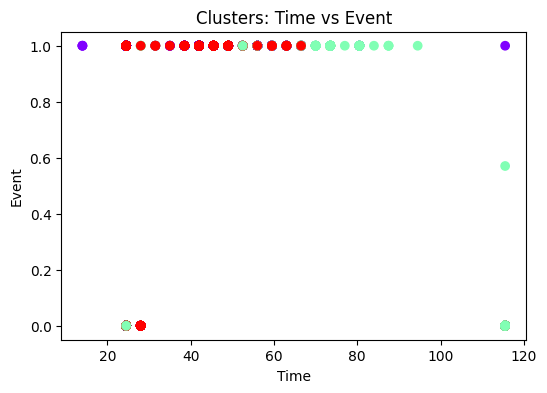

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Select only numeric columns
X = df.select_dtypes(include=['float64','int64'])

# Handle missing values (fill with mean)
X = X.fillna(X.mean())

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply KMeans clustering with chosen k (example: 3)
kmeans = KMeans(n_clusters=3, random_state=0)
kmeans.fit(X_scaled)
y_kmeans = kmeans.predict(X_scaled)

# Add cluster labels to dataframe
df['Cluster'] = y_kmeans

print("Cluster Centers:")
print(kmeans.cluster_centers_)

# Scatter plots + Elbow for every feature pair
numeric_cols = X.columns

for i in range(len(numeric_cols)):
    for j in range(i+1, len(numeric_cols)):
        # Subset data for the two features
        pair_data = X[[numeric_cols[i], numeric_cols[j]]]

        # Elbow method for this pair
        inertia = []
        K = range(1, 11)
        for k in K:
            km = KMeans(n_clusters=k, random_state=0)
            km.fit(pair_data)
            inertia.append(km.inertia_)

        plt.figure(figsize=(5,4))
        plt.plot(K, inertia, 'bx-')
        plt.xlabel('k')
        plt.ylabel('Inertia')
        plt.title(f'Elbow Method: {numeric_cols[i]} vs {numeric_cols[j]}')
        plt.show()

        # Scatter plot with clusters for this pair
        plt.figure(figsize=(6,4))
        plt.scatter(pair_data[numeric_cols[i]], pair_data[numeric_cols[j]], c=y_kmeans, cmap='rainbow')
        plt.xlabel(numeric_cols[i])
        plt.ylabel(numeric_cols[j])
        plt.title(f'Clusters: {numeric_cols[i]} vs {numeric_cols[j]}')
        plt.show()
